# Saaz models: mutant emergence and CNV competition

A two-genotype, haploid Wright–Fisher model starts with an all-wild-type population. Wild type has fitness $1$; the mutant has fitness $1+s$. Each wild-type offspring mutates to the mutant with probability $\delta$ per generation. There is **no back mutation**: the mutant genotype is absorbing under mutation, and a fully mutant population stays fully mutant.

For mutant frequency $x_t$, selection followed by mutation gives

$$q_t=\delta+(1-\delta)\frac{(1+s)x_t}{1+s x_t},\qquad
M_{t+1}\sim\mathrm{Binomial}(N,q_t),\qquad x_{t+1}=M_{t+1}/N.$$

The simulator checks **every generation** for the first time $x_t\geq 0.20$ and reports whether that has happened by each generation in `g`. Each parameter combination has independent stochastic replicates. At each sampled generation, a population size is called successful when **more than half** its replicates have reached 20%. The combined heatmaps use burgundy when neither population size succeeds, turquoise for success at 300M, and green for success at 600k. The 600k layer is drawn last, so it remains visible when both succeed. The underlying fraction of successful replicates is retained in `results["hit_probability"]`. `N` affects drift and mutation supply through the binomial population model.

The two probability heatmaps show the **estimated probability** of reaching 20% by generation 80 separately for each population size, using the fraction of 101 replicates that crossed the threshold. Their color bars share a 0–1 scale.

The final section adds a three-genotype model in which aneuploid and segmental CNV mutations compete. The absorbing-state assumption above applies only to the introductory two-genotype model; the final model includes aneuploid-to-wild-type reversion.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Circle, ConnectionPatch, Ellipse, FancyArrowPatch, Rectangle
from matplotlib.ticker import LogFormatterMathtext, LogLocator, MaxNLocator

# Named swatches from the repository's vitra_palette.py.
VITRA_BURGUNDY = "#7B3048"    # failure
VITRA_GRASS_GREEN = "#8FB52C"  # 600k success
VITRA_TEAL_BLUE = "#3B9290"    # 300M success
VITRA_ORANGE = "#E45A21"       # aneuploid
VITRA_DUSTY_ROSE = "#C45870"   # segmental CNV
VITRA_TENDER_YELLOW = "#E0CA72"  # generic mutant in the first model
VITRA_PAPER = "#FAF8F4"
VITRA_INK = "#273033"

# Match the C059 serif and STIX math used in fig1_experimental_design.pdf.
font_root = Path("/usr/share/fonts/opentype/urw-base35")
for font_name in ("C059-Roman.otf", "C059-Bold.otf", "C059-Italic.otf", "C059-BdIta.otf"):
    font_path = font_root / font_name
    if font_path.exists():
        font_manager.fontManager.addfont(str(font_path))
paper_font = (
    font_manager.FontProperties(fname=str(font_root / "C059-Roman.otf")).get_name()
    if (font_root / "C059-Roman.otf").exists() else "DejaVu Serif"
)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": paper_font,
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

## Inputs

Edit this cell to change the selection coefficients `s`, mutation rates `delta`, population sizes `N`, sampled generations `g`, or the number of replicate populations. The displayed defaults span $s=0.20$–$0.80$, $\delta=10^{-10}$–$10^{-3}$, and $N=600{,}000$ or $3\times10^8$. `g` controls the reporting times; the model still simulates each intervening generation.

In [2]:
s = np.linspace(0.20, 0.80, 31)
delta = np.geomspace(1e-10, 1e-3, 29)
N = np.array([600_000, 300_000_000])
g = np.arange(10, 81, 10)

threshold = 0.20
n_replicates = 101  # odd count avoids a 50/50 tie
seed = 2026        # reproducible stochastic runs


## Model diagram

The arrow is one-way: wild type can produce mutants, while mutants never revert. Selection favors the mutant; binomial sampling adds finite-population drift each generation.

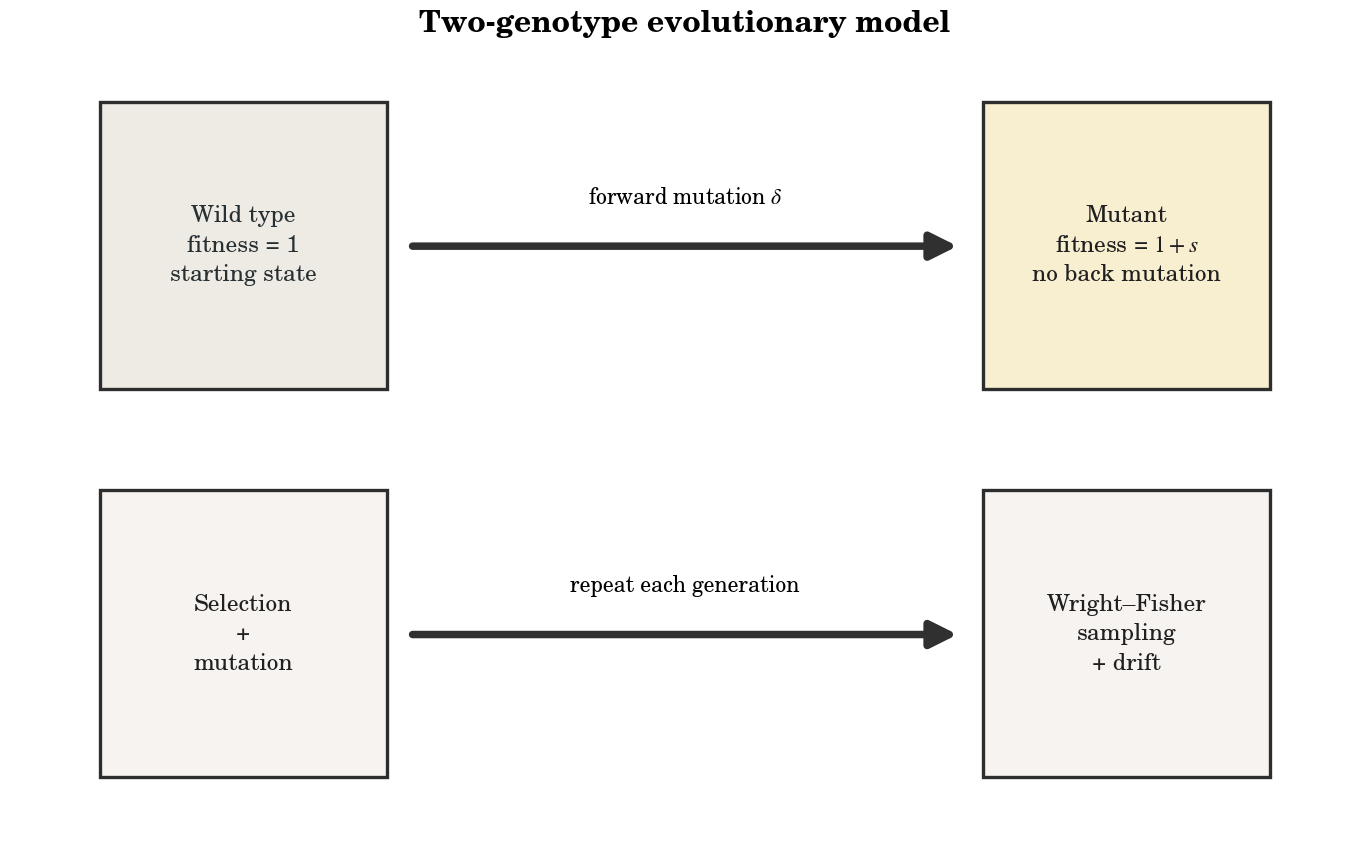

In [3]:
def draw_square(ax, x, y, side, text, facecolor, *, textcolor="#202020", fontsize=13):
    """Draw a square card using equal data units on both axes."""
    ax.add_patch(Rectangle(
        (x, y), side, side, facecolor=facecolor,
        edgecolor="#2D2D2D", linewidth=2.0,
    ))
    ax.text(x + side / 2, y + side / 2, text, ha="center", va="center",
            color=textcolor, fontsize=fontsize, linespacing=1.45)


fig, ax = plt.subplots(figsize=(11.8, 7.0), layout="constrained")
ax.set_xlim(0, 12)
ax.set_ylim(0, 7)
ax.set_aspect("equal")
ax.axis("off")

side = 2.55
draw_square(ax, 0.8, 4.0, side, "Wild type\nfitness = 1\nstarting state",
            "#EEEAE4", textcolor=VITRA_INK, fontsize=14)
draw_square(ax, 8.65, 4.0, side, "Mutant\nfitness = $1+s$\nno back mutation",
            "#F8EED0", fontsize=14)
ax.add_patch(FancyArrowPatch(
    (3.55, 5.27), (8.45, 5.27), arrowstyle="-|>",
    mutation_scale=33, linewidth=4.5, color="#303030",
))
ax.text(6.0, 5.65, r"forward mutation $\delta$", ha="center", fontsize=13)

draw_square(ax, 0.8, 0.55, side, "Selection\n+\nmutation", "#F6F3F0", fontsize=14)
draw_square(ax, 8.65, 0.55, side, "Wright–Fisher\nsampling\n+ drift",
            "#F6F3F0", fontsize=14)
ax.add_patch(FancyArrowPatch(
    (3.55, 1.82), (8.45, 1.82), arrowstyle="-|>",
    mutation_scale=33, linewidth=4.5, color="#303030",
))
ax.text(6.0, 2.20, "repeat each generation", ha="center", fontsize=13)
ax.set_title("Two-genotype evolutionary model", fontsize=18, weight="bold", pad=12)
plt.show()

## Wright–Fisher simulation

`simulate_wright_fisher_grid` accepts scalar or one-dimensional arrays for `s`, `delta`, and `N`, plus a one-dimensional integer array `g`. Its result arrays use the axis order **generation × population size × selection × mutation rate**. `hit_probability` is the fraction of replicate populations that have ever crossed the threshold by each sampled generation; `success` is the binary classification used in the heatmaps.

In [4]:
def _as_1d(values, name, dtype=float):
    array = np.atleast_1d(np.asarray(values, dtype=dtype))
    if array.ndim != 1 or array.size == 0 or not np.all(np.isfinite(array)):
        raise ValueError(f"{name} must be a nonempty, finite one-dimensional array or scalar")
    return array


def simulate_wright_fisher_grid(s, delta, N, g, *, threshold=0.20,
                                 n_replicates=101, seed=2026):
    '''Estimate first-passage success for a grid of two-genotype WF populations.'''
    s = _as_1d(s, "s")
    delta = _as_1d(delta, "delta")
    population = _as_1d(N, "N")
    generations = _as_1d(g, "g")

    if np.any(s < 0) or np.any(np.diff(s) <= 0):
        raise ValueError("s must be nonnegative and strictly increasing")
    if np.any((delta < 0) | (delta > 1)) or np.any(np.diff(delta) <= 0):
        raise ValueError("delta must lie in [0, 1] and be strictly increasing")
    if np.any(population <= 0) or np.any(population != np.floor(population)) or np.any(np.diff(population) <= 0):
        raise ValueError("N must contain positive, strictly increasing integers")
    if np.any(generations < 0) or np.any(generations != np.floor(generations)) or np.any(np.diff(generations) <= 0):
        raise ValueError("g must contain nonnegative, strictly increasing integers")
    if not 0 < threshold <= 1:
        raise ValueError("threshold must lie in (0, 1]")
    if not isinstance(n_replicates, (int, np.integer)) or n_replicates < 1:
        raise ValueError("n_replicates must be a positive integer")

    population = population.astype(np.int64)
    generations = generations.astype(np.int64)
    pop_axis = population[:, None, None, None]
    s_axis = s[None, :, None, None]
    delta_axis = delta[None, None, :, None]
    shape = (len(population), len(s), len(delta), n_replicates)
    mutant_count = np.zeros(shape, dtype=np.int64)  # all wild type at generation 0
    hit = np.zeros(shape, dtype=bool)
    hit_probability = np.empty((len(generations), *shape[:-1]), dtype=float)
    sample_index = {int(t): i for i, t in enumerate(generations)}
    if 0 in sample_index:
        hit_probability[sample_index[0]] = hit.mean(axis=-1)

    rng = np.random.default_rng(seed)
    for t in range(1, int(generations[-1]) + 1):
        x = mutant_count / pop_axis
        selected = (1 + s_axis) * x / (1 + s_axis * x)
        offspring_mutant_probability = delta_axis + (1 - delta_axis) * selected
        mutant_count = rng.binomial(pop_axis, offspring_mutant_probability)
        hit |= mutant_count / pop_axis >= threshold
        if t in sample_index:
            hit_probability[sample_index[t]] = hit.mean(axis=-1)

    return {
        "s": s, "delta": delta, "N": population, "g": generations,
        "threshold": threshold, "n_replicates": n_replicates,
        "hit_probability": hit_probability,
        "success": hit_probability > 0.5,
    }

## Example simulation trajectories

These runs illustrate raw stochastic behavior before aggregation. Each line is one population. **Green means N = 600k and blue means N = 300M**, matching the population labels throughout the notebook. Solid lines reached 20% by generation 80; faded dashed lines did not. Dots mark generations in `g`, and the dark dashed horizontal line is the 20% reference. The middle panels compare the two population sizes at the same $s$ and $\delta$.

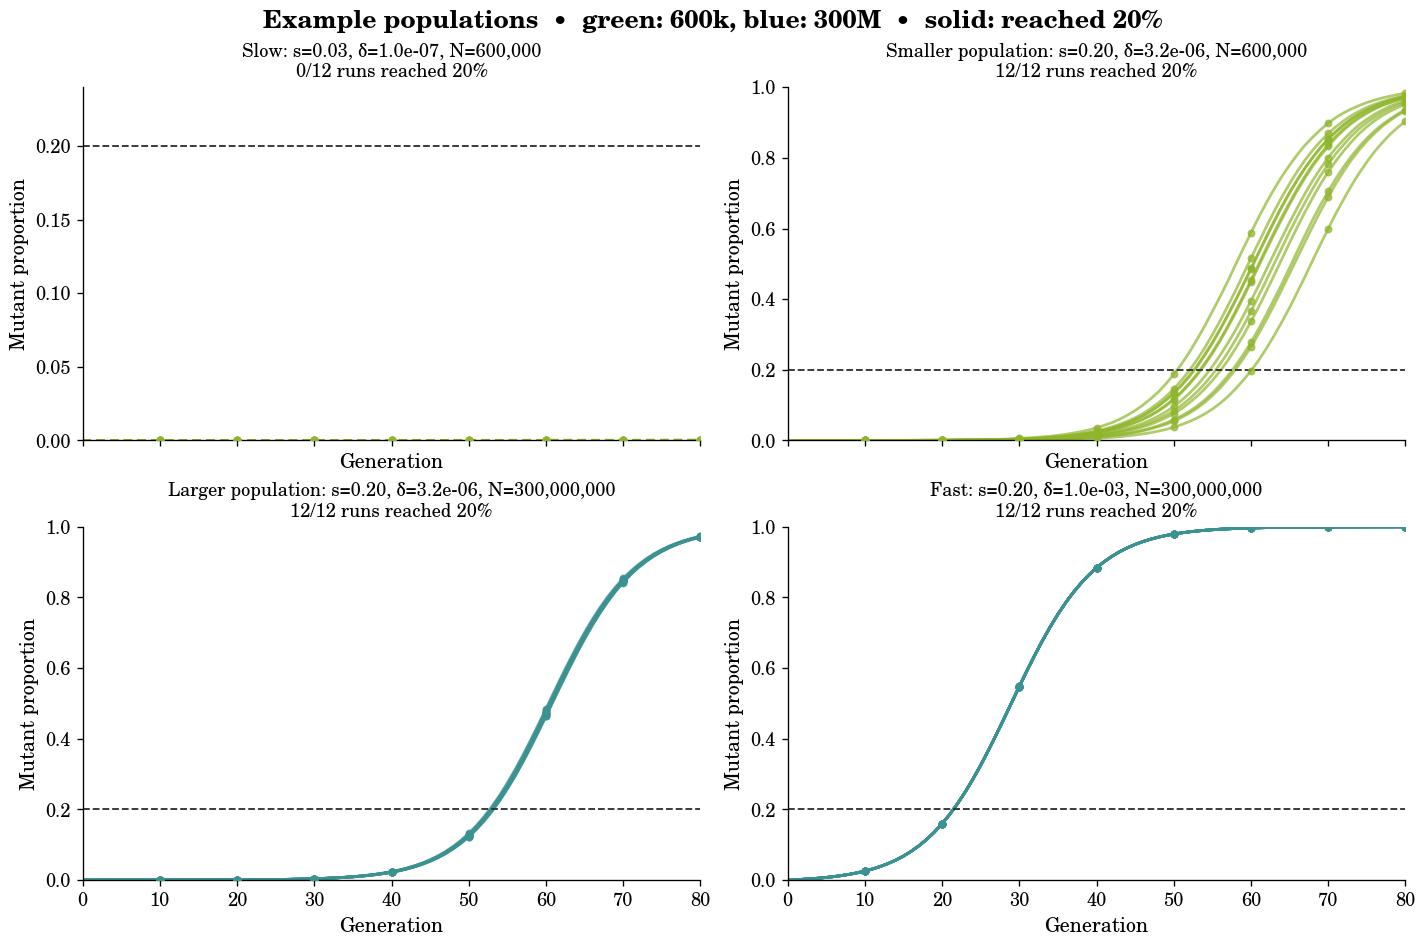

In [5]:
def simulate_trajectories(s, delta, N, g, *, n_replicates=12, seed=0):
    '''Return mutant frequencies for every generation through max(g).'''
    max_generation = int(np.max(g))
    frequencies = np.zeros((n_replicates, max_generation + 1))
    mutant_count = np.zeros(n_replicates, dtype=np.int64)
    rng = np.random.default_rng(seed)
    for t in range(1, max_generation + 1):
        x = mutant_count / N
        selected = (1 + s) * x / (1 + s * x)
        q = delta + (1 - delta) * selected
        mutant_count = rng.binomial(N, q)
        frequencies[:, t] = mutant_count / N
    return frequencies


examples = [
    ("Slow", 0.03, 1e-7, 600_000),
    ("Smaller population", 0.20, 3.2e-6, 600_000),
    ("Larger population", 0.20, 3.2e-6, 300_000_000),
    ("Fast", 0.20, 1e-3, 300_000_000),
]
fig, axes = plt.subplots(2, 2, figsize=(11.8, 7.8), sharex=True, layout="constrained")
for index, (label, selection, mutation, pop_size) in enumerate(examples):
    ax = axes.flat[index]
    paths = simulate_trajectories(selection, mutation, pop_size, g,
                                  n_replicates=12, seed=seed + index)
    reached = np.any(paths >= threshold, axis=1)
    times = np.arange(paths.shape[1])
    for path, did_reach in zip(paths, reached):
        color = VITRA_GRASS_GREEN if pop_size == 600_000 else VITRA_TEAL_BLUE
        line_style = "-" if did_reach else (0, (3, 2))
        opacity = 0.70 if did_reach else 0.38
        ax.plot(times, path, color=color, linewidth=1.65,
                linestyle=line_style, alpha=opacity)
        ax.scatter(g, path[g], color=color, s=14,
                   alpha=opacity, zorder=3)
    ax.axhline(threshold, color="#303030", linestyle="--", linewidth=1.1)
    ax.set_xlim(0, g[-1])
    ax.set_ylim(0, min(1, max(0.24, paths.max() * 1.08)))
    ax.set_title(f"{label}: s={selection:.2f}, δ={mutation:.1e}, N={pop_size:,}\n"
                 f"{reached.sum()}/{len(reached)} runs reached 20%", fontsize=11)
    ax.set_xlabel("Generation")
    ax.set_ylabel("Mutant proportion")
fig.suptitle("Example populations  •  green: 600k, blue: 300M  •  solid: reached 20%",
             fontsize=15, weight="bold")
plt.show()

In [6]:
results = simulate_wright_fisher_grid(
    s=s, delta=delta, N=N, g=g,
    threshold=threshold, n_replicates=n_replicates, seed=seed,
)
print("Hit probability shape (g, N, s, delta):", results["hit_probability"].shape)
print(f"Success cutoff: {n_replicates // 2 + 1} of {n_replicates} runs")
print("Overlay: burgundy = neither N succeeds; turquoise = 300M succeeds; green = 600k succeeds")

Hit probability shape (g, N, s, delta): (8, 2, 31, 29)
Success cutoff: 51 of 101 runs
Overlay: burgundy = neither N succeeds; turquoise = 300M succeeds; green = 600k succeeds


## Combined first-passage heatmaps

Each panel is one sampled generation at 10, 20, 30, 40, 50, and 60. Burgundy means **both** population sizes failed to reach 20% in a majority of their 101 replicates. Turquoise shows success at **300M**; green shows success at **600k**. The 300M result is painted first and the 600k result on top, so green is visible where both succeed. Selection coefficient $s$ is horizontal and mutation rate $\delta$ is vertical on a log scale. The colors are Burgundy, Teal Blue, and Grass Green from the local Vitra palette.

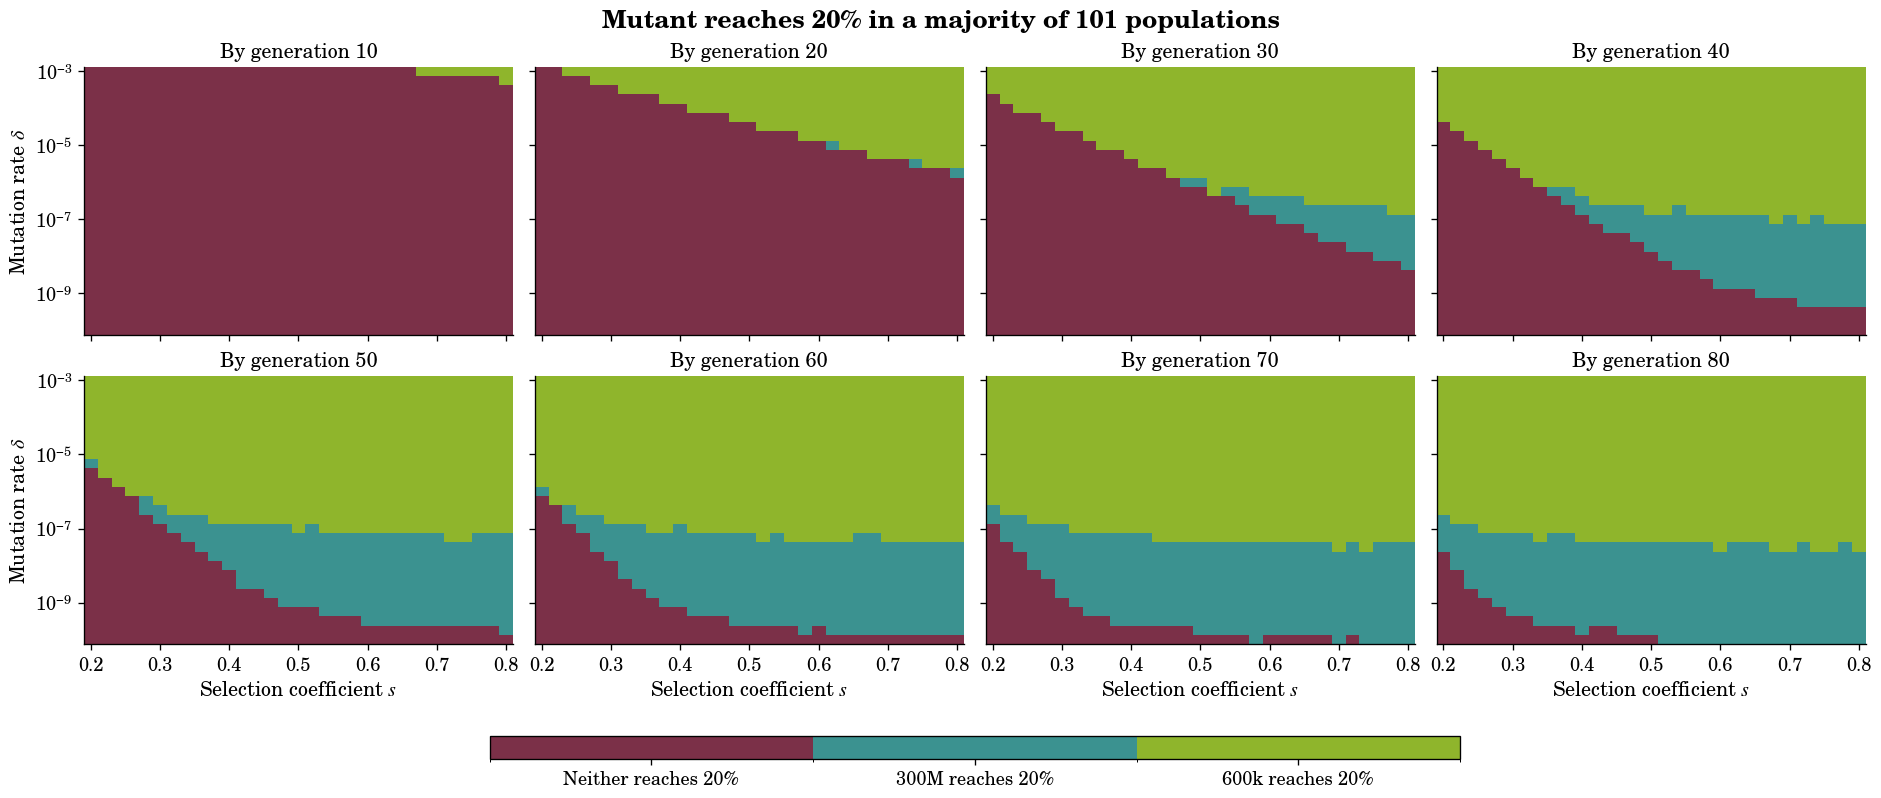

In [7]:
def _cell_edges(values, *, logarithmic=False):
    values = np.asarray(values, dtype=float)
    if logarithmic and np.any(values <= 0):
        raise ValueError("Logarithmic heatmap coordinates must be positive")
    coordinates = np.log10(values) if logarithmic else values
    if len(values) == 1:
        half_width = 0.15 if logarithmic else max(abs(values[0]) * 0.1, 0.001)
        edges = np.array([coordinates[0] - half_width, coordinates[0] + half_width])
    else:
        midpoints = (coordinates[:-1] + coordinates[1:]) / 2
        edges = np.concatenate((
            [coordinates[0] - (midpoints[0] - coordinates[0])],
            midpoints,
            [coordinates[-1] + (coordinates[-1] - midpoints[-1])],
        ))
    return 10 ** edges if logarithmic else edges


def plot_success_heatmaps(results):
    population_sizes = results["N"]
    if not (600_000 in population_sizes and 300_000_000 in population_sizes):
        raise ValueError("The overlay requires N = 600,000 and N = 300,000,000")
    small_index = int(np.flatnonzero(population_sizes == 600_000)[0])
    large_index = int(np.flatnonzero(population_sizes == 300_000_000)[0])
    s_edges = _cell_edges(results["s"])
    delta_edges = _cell_edges(results["delta"], logarithmic=True)
    s_min, s_max = results["s"][0], results["s"][-1]
    tick_step = 0.1 if s_max - s_min > 0.3 else 0.05
    s_ticks = np.arange(tick_step, s_max + tick_step / 2, tick_step)
    s_ticks = s_ticks[s_ticks >= s_min]
    s_ticks = np.unique(np.r_[s_min, s_ticks])
    n_cols = min(4, len(results["g"]))
    n_rows = int(np.ceil(len(results["g"]) / n_cols))
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(3.9 * n_cols, 3.3 * n_rows),
        sharex=True, sharey=True, constrained_layout=True, squeeze=False,
    )

    for time_index, generation in enumerate(results["g"]):
        row, col = divmod(time_index, n_cols)
        ax = axes[row, col]
        large_success = results["success"][time_index, large_index].T
        small_success = results["success"][time_index, small_index].T
        background = np.zeros_like(large_success, dtype=float)

        # Layer order matters: both fail -> 300M succeeds -> 600k succeeds.
        ax.pcolormesh(s_edges, delta_edges, background,
                      cmap=ListedColormap([VITRA_BURGUNDY]), shading="flat", rasterized=True)
        ax.pcolormesh(s_edges, delta_edges,
                      np.ma.masked_where(~large_success, large_success.astype(float)),
                      cmap=ListedColormap([VITRA_TEAL_BLUE]), shading="flat", rasterized=True)
        ax.pcolormesh(s_edges, delta_edges,
                      np.ma.masked_where(~small_success, small_success.astype(float)),
                      cmap=ListedColormap([VITRA_GRASS_GREEN]), shading="flat", rasterized=True)

        ax.set_yscale("log")
        ax.set_xticks(s_ticks)
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=6))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
        ax.grid(False)
        ax.set_title(f"By generation {generation}", fontsize=12)
        if col == 0:
            ax.set_ylabel(r"Mutation rate $\delta$")
        if row == n_rows - 1:
            ax.set_xlabel(r"Selection coefficient $s$")
    for ax in axes.ravel()[len(results["g"]):]:
        ax.set_visible(False)

    legend_map = ScalarMappable(
        cmap=ListedColormap([VITRA_BURGUNDY, VITRA_TEAL_BLUE, VITRA_GRASS_GREEN]),
        norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3),
    )
    cbar = fig.colorbar(
        legend_map, ax=axes.ravel()[:len(results["g"])].tolist(),
        orientation="horizontal", ticks=[0, 1, 2],
        fraction=0.04, pad=0.06, shrink=0.75, aspect=42,
    )
    cbar.ax.set_xticklabels([
        "Neither reaches 20%", "300M reaches 20%", "600k reaches 20%",
    ])
    fig.suptitle(
        f"Mutant reaches 20% in a majority of {results['n_replicates']} populations",
        fontsize=15, fontweight="bold",
    )
    return fig, axes


fig, axes = plot_success_heatmaps(results)
plt.show()

## Generation 80: probability of reaching 20%

These two heatmaps show the fraction of 101 independent replicate populations that reached 20% at any time by generation 80. Color varies continuously from burgundy (0) through a pale midpoint (0.5) to the population color (1). Both color bars use the same 0–1 scale, so their probability values are directly comparable. The 600k plot uses Grass Green; the 300M plot uses Teal Blue.

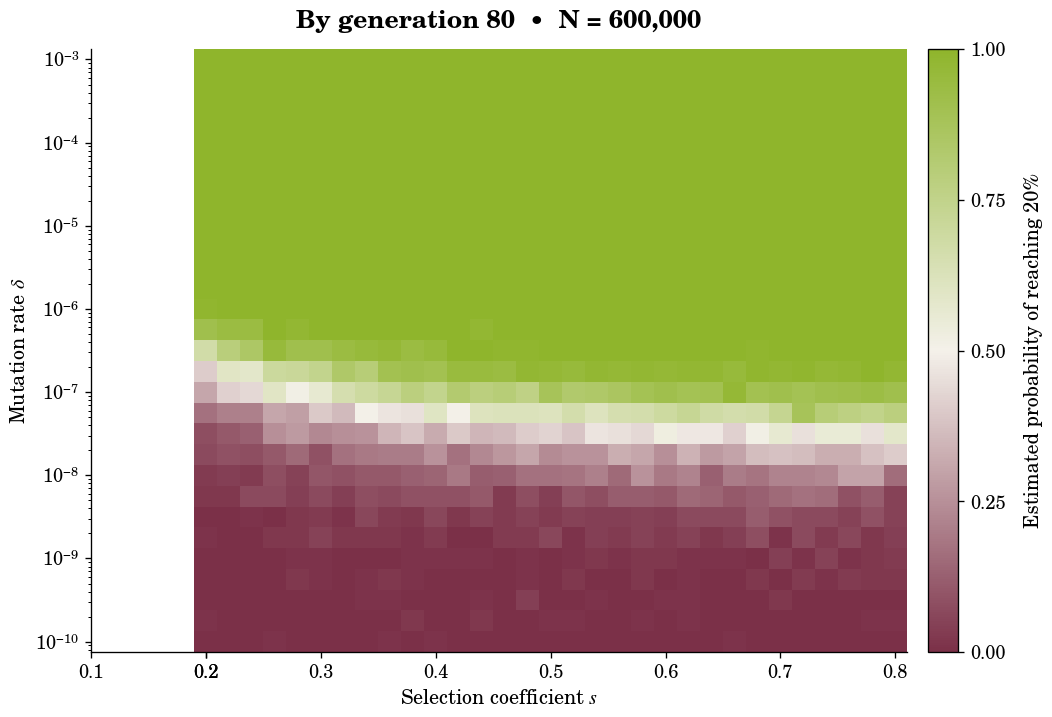

In [8]:
def plot_probability_heatmap(results, population_size, generation=80, *, high_color):
    generation_index = np.flatnonzero(results["g"] == generation)
    population_index = np.flatnonzero(results["N"] == population_size)
    if len(generation_index) != 1 or len(population_index) != 1:
        raise ValueError("The requested generation and population size must be in results")

    probabilities = results["hit_probability"][generation_index[0], population_index[0]].T
    s_edges = _cell_edges(results["s"])
    delta_edges = _cell_edges(results["delta"], logarithmic=True)
    probability_colors = LinearSegmentedColormap.from_list(
        f"vitra_probability_{population_size}",
        [(0.0, VITRA_BURGUNDY), (0.5, "#F4F1EA"), (1.0, high_color)],
    )

    fig, ax = plt.subplots(figsize=(8.7, 5.9), layout="constrained")
    image = ax.pcolormesh(
        s_edges, delta_edges, probabilities, cmap=probability_colors,
        vmin=0, vmax=1, shading="flat", rasterized=True,
    )
    ax.set_yscale("log")
    ax.set_xlim(s_edges[0], s_edges[-1])
    ax.set_ylim(delta_edges[0], delta_edges[-1])
    ax.set_xticks(np.r_[results["s"][0], np.arange(0.1, results["s"][-1] + 0.01, 0.1)])
    ax.yaxis.set_major_locator(LogLocator(base=10, numticks=8))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
    ax.set_xlabel(r"Selection coefficient $s$")
    ax.set_ylabel(r"Mutation rate $\delta$")
    ax.set_title(
        f"By generation {generation}  •  N = {population_size:,}",
        fontsize=15, fontweight="bold", pad=13,
    )
    colorbar = fig.colorbar(image, ax=ax, ticks=np.linspace(0, 1, 5), pad=0.025)
    colorbar.set_label("Estimated probability of reaching 20%", labelpad=11)
    return fig, ax


fig, ax = plot_probability_heatmap(
    results, 600_000, generation=80, high_color=VITRA_GRASS_GREEN,
)
plt.show()

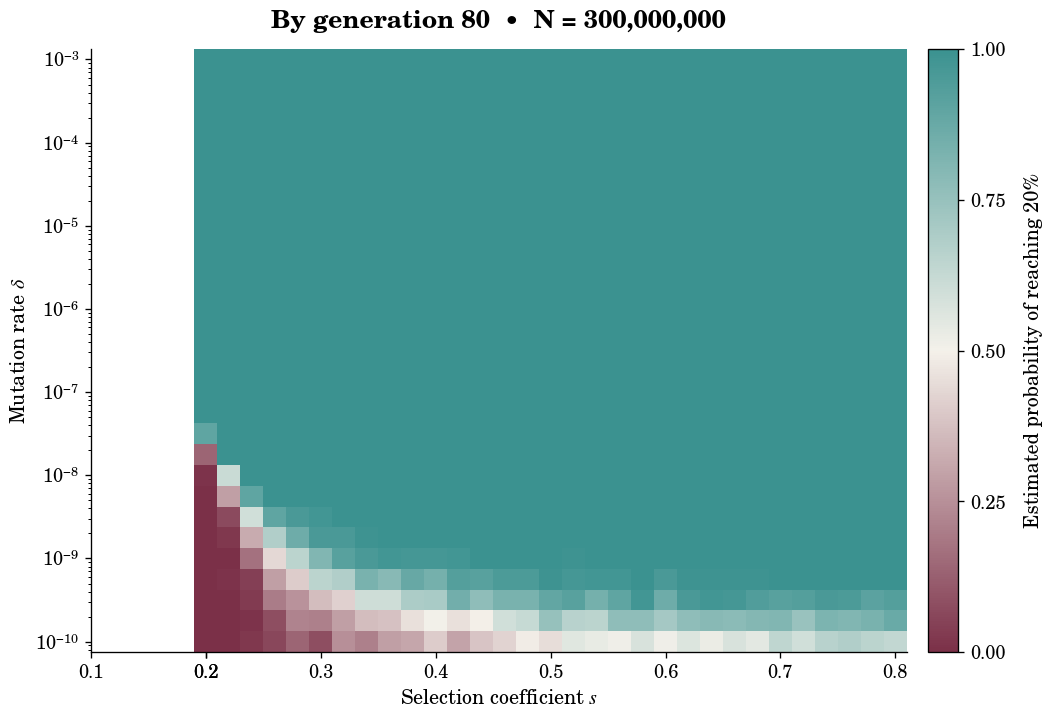

In [9]:
fig, ax = plot_probability_heatmap(
    results, 300_000_000, generation=80, high_color=VITRA_TEAL_BLUE,
)
plt.show()

## Competing aneuploid and segmental CNV model

This three-genotype Wright–Fisher model starts entirely wild type (W). Wild-type offspring become aneuploid (A) at rate $\delta_A$ or segmental CNV (C) at rate $\delta_C$. **Aneuploid offspring revert to wild type at the same rate $\delta_A$.** Segmental CNVs do not revert, and there is no direct A-to-C transition. The two WT mutation outcomes are exclusive, so $\delta_A+\delta_C\leq1$. Their fitnesses are $1+s_A$ and $1+s_C$.

For current counts $W,A,C$ with $W+A+C=N$, let $D=W+(1+s_A)A+(1+s_C)C$. Selection followed by mutation gives

$$q_A=\frac{(1-\delta_A)(1+s_A)A+\delta_A W}{D},\qquad
q_C=\frac{(1+s_C)C+\delta_C W}{D},\qquad
q_W=\frac{(1-\delta_A-\delta_C)W+\delta_A(1+s_A)A}{D}.$$

The next generation is a **multinomial** sample of $N$ offspring with probabilities $(q_W,q_A,q_C)$. The heatmaps show the **segmental fraction among all CNV cells** at generation 80: $C/(A+C)$ within each replicate population, averaged across replicates. Wild-type cells are excluded from this denominator. A replicate with no CNV cells contributes zero; at the chosen aneuploid formation rate, that case is negligible by the sampled generations. The simulator also retains the probability that $C>A$ as a separate, unplotted outcome.


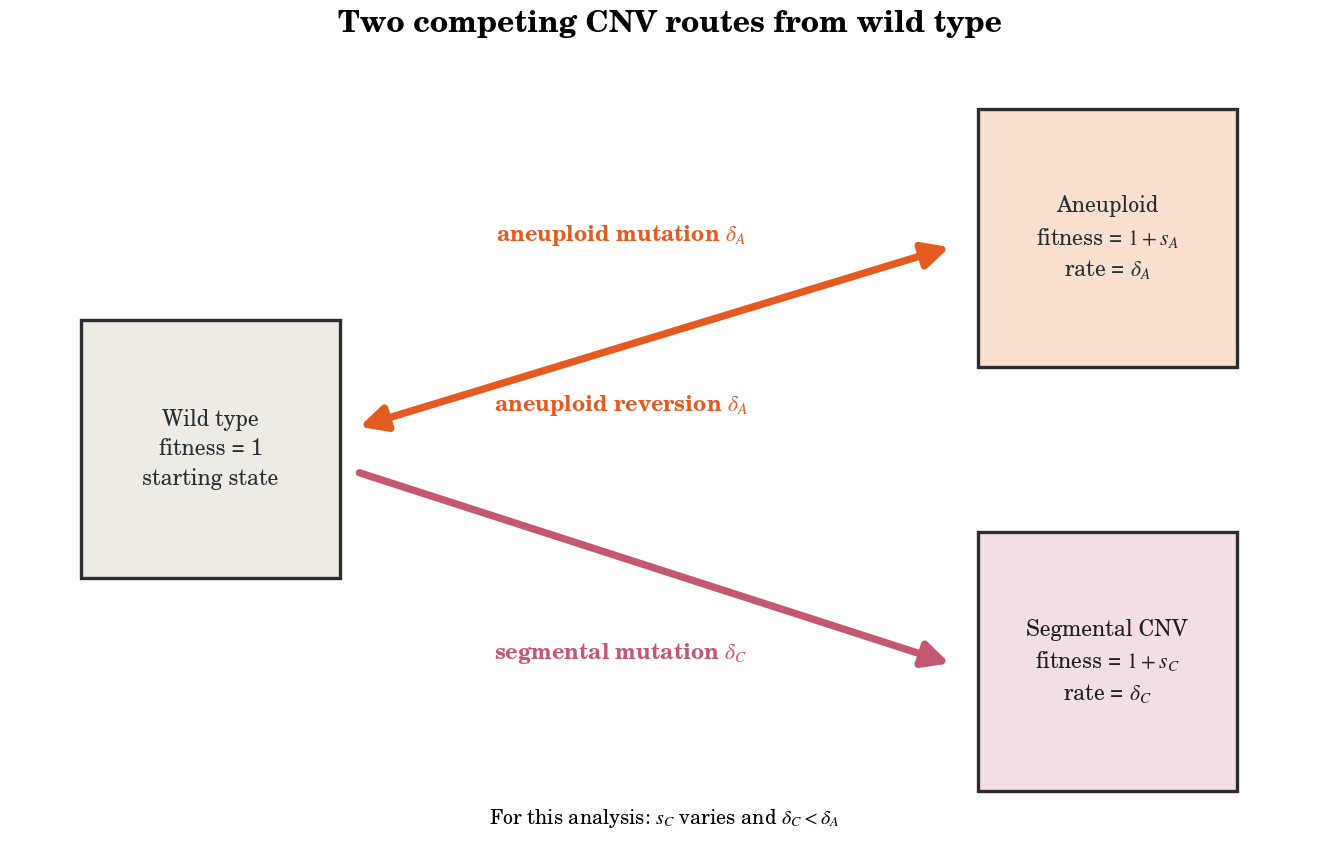

In [10]:
fig, ax = plt.subplots(figsize=(11.8, 7.1), layout="constrained")
ax.set_xlim(0, 12)
ax.set_ylim(0, 7.3)
ax.set_aspect("equal")
ax.axis("off")

side = 2.35
draw_square(ax, 0.65, 2.48, side,
            "Wild type\nfitness = 1\nstarting state",
            "#EEEAE4", textcolor=VITRA_INK, fontsize=13)
draw_square(ax, 8.80, 4.40, side,
            "Aneuploid\nfitness = $1+s_A$\nrate = $\\delta_A$",
            "#F9DFCD", textcolor=VITRA_INK, fontsize=13)
draw_square(ax, 8.80, 0.55, side,
            "Segmental CNV\nfitness = $1+s_C$\nrate = $\\delta_C$",
            "#F4DEE5", fontsize=13)

ax.add_patch(FancyArrowPatch(
    (3.15, 3.85), (8.57, 5.50), arrowstyle="<|-|>",
    mutation_scale=32, linewidth=4.4, color=VITRA_ORANGE,
))
ax.add_patch(FancyArrowPatch(
    (3.15, 3.45), (8.57, 1.70), arrowstyle="-|>",
    mutation_scale=32, linewidth=4.4, color=VITRA_DUSTY_ROSE,
))
ax.text(5.55, 5.55, r"aneuploid mutation $\delta_A$", color=VITRA_ORANGE,
        ha="center", fontsize=13, weight="bold")
ax.text(5.55, 4.00, r"aneuploid reversion $\delta_A$", color=VITRA_ORANGE,
        ha="center", fontsize=13, weight="bold")
ax.text(5.55, 1.75, r"segmental mutation $\delta_C$", color=VITRA_DUSTY_ROSE,
        ha="center", fontsize=13, weight="bold")
ax.text(5.95, 0.25, r"For this analysis: $s_C$ varies and $\delta_C<\delta_A$",
        ha="center", fontsize=12)
ax.set_title("Two competing CNV routes from wild type", fontsize=18, weight="bold", pad=10)
plt.show()

### Competing-model inputs

The fixed aneuploid setting is $s_A=0.07$ (fitness $1.07$) and $\delta_A=10^{-3}$. The selection coefficient is a rounded value within the revised aneuploid fitness range of approximately $1.04$–$1.08$. The high aneuploid formation-rate scenario is motivated by the approximately $1.7\times10^{-3}$ rate inferred for chromosome gain under **heat stress in diploid yeast** by [Kohanovski et al. (2024)](https://academic.oup.com/mbe/article/41/3/msae052/7617296). That estimate is not a direct rate for chromosome VIII gain in these haploid fluconazole experiments. The Sakrikar study measured lower CNV formation rates of $1.4\times10^{-5}$ at 16 ng/µL and $8\times10^{-6}$ at 32 ng/µL using a different chromosome-V reporter, which can also recover local amplifications. Thus $\delta_A=10^{-3}$ is an exploratory high-supply assumption, not a fitted rate for the experiment. Aneuploid offspring revert to wild type at the same rate $\delta_A$ used for formation. This equality is a modeling assumption, not a fitted reversion estimate.

The segmental grid spans $s_C=0.07$–$0.20$ in increments of $0.0025$ and $\delta_C=10^{-8}$–$10^{-3}$ with ten logarithmic intervals per order of magnitude, including both endpoints. Segmental formation is therefore equal to or lower than the fixed aneuploid rate. Population sizes, sampled generations, replicate count, and seed are inherited from the first model. The illustrated low-rate point is $s_C=0.10$, $\delta_C=10^{-6}$. The short-view and long-view trajectory panels use the same replicate simulations, extended to generation 300.

In [11]:
aneuploid_s = 0.07
aneuploid_delta = 1e-3
segmental_s = np.round(np.linspace(0.07, 0.20, 53), 4)
# Five decades with ten intervals per decade, including both endpoints.
segmental_delta = np.geomspace(1e-8, aneuploid_delta, 51)
competition_seed = seed + 1

print(f"Aneuploid: s={aneuploid_s:g}, delta={aneuploid_delta:g}")
print(f"Segmental grid: s={segmental_s[0]:.2f}–{segmental_s[-1]:.2f}; "
      f"delta={segmental_delta[0]:.1e}–{segmental_delta[-1]:.1e}")

Aneuploid: s=0.07, delta=0.001
Segmental grid: s=0.07–0.20; delta=1.0e-08–1.0e-03


In [12]:
def competing_offspring_probabilities(count_A, count_C, N,
                                       s_aneuploid, delta_aneuploid,
                                       s_segmental, delta_segmental):
    """Selected-parent offspring probabilities with symmetric WT↔A mutation."""
    count_W = N - count_A - count_C
    total_fitness = N + s_aneuploid * count_A + s_segmental * count_C
    q_A = ((1 - delta_aneuploid) * (1 + s_aneuploid) * count_A
           + delta_aneuploid * count_W) / total_fitness
    q_C = ((1 + s_segmental) * count_C
           + delta_segmental * count_W) / total_fitness
    return q_A, q_C


def simulate_competing_cnv_grid(s_aneuploid, delta_aneuploid,
                                s_segmental, delta_segmental, N, g,
                                *, n_replicates=101, seed=2027):
    """Simulate WT, aneuploid, and segmental CNV competition on a parameter grid."""
    s_segmental = _as_1d(s_segmental, "s_segmental")
    delta_segmental = _as_1d(delta_segmental, "delta_segmental")
    population = _as_1d(N, "N")
    generations = _as_1d(g, "g")
    if not np.isfinite(s_aneuploid) or s_aneuploid < 0:
        raise ValueError("s_aneuploid must be finite and nonnegative")
    if not np.isfinite(delta_aneuploid) or not 0 < delta_aneuploid <= 1:
        raise ValueError("delta_aneuploid must lie in (0, 1]")
    if np.any(s_segmental < 0) or np.any(np.diff(s_segmental) <= 0):
        raise ValueError("Segmental s must be nonnegative and strictly increasing")
    if np.any(delta_segmental < 0) or np.any(delta_segmental > delta_aneuploid) or np.any(np.diff(delta_segmental) <= 0):
        raise ValueError("Every segmental delta must be at or below aneuploid delta and be increasing")
    if delta_aneuploid + delta_segmental[-1] > 1:
        raise ValueError("The two mutation probabilities must sum to at most 1")
    if np.any(population <= 0) or np.any(population != np.floor(population)) or np.any(np.diff(population) <= 0):
        raise ValueError("N must contain positive, strictly increasing integers")
    if np.any(generations < 0) or np.any(generations != np.floor(generations)) or np.any(np.diff(generations) <= 0):
        raise ValueError("g must contain nonnegative, strictly increasing integers")
    if not isinstance(n_replicates, (int, np.integer)) or n_replicates < 1:
        raise ValueError("n_replicates must be a positive integer")

    population = population.astype(np.int64)
    generations = generations.astype(np.int64)
    pop_axis = population[:, None, None, None]
    s_axis = s_segmental[None, :, None, None]
    delta_axis = delta_segmental[None, None, :, None]
    shape = (len(population), len(s_segmental), len(delta_segmental), n_replicates)
    aneuploid_count = np.zeros(shape, dtype=np.int64)
    segmental_count = np.zeros(shape, dtype=np.int64)
    out_shape = (len(generations), *shape[:-1])
    segmental_outnumbers = np.empty(out_shape)
    mean_segmental_cnv_share = np.empty(out_shape)
    segmental_majority = np.empty(out_shape)
    segmental_largest_genotype = np.empty(out_shape)
    mean_aneuploid_frequency = np.empty(out_shape)
    mean_segmental_frequency = np.empty(out_shape)
    sampled_times = {int(t): i for i, t in enumerate(generations)}

    def record(i):
        wild_type_count = pop_axis - aneuploid_count - segmental_count
        segmental_outnumbers[i] = (segmental_count > aneuploid_count).mean(axis=-1)
        total_cnv_count = aneuploid_count + segmental_count
        segmental_share = np.divide(
            segmental_count, total_cnv_count,
            out=np.zeros(shape, dtype=float), where=total_cnv_count > 0,
        )
        mean_segmental_cnv_share[i] = segmental_share.mean(axis=-1)
        segmental_majority[i] = (2 * segmental_count > pop_axis).mean(axis=-1)
        segmental_largest_genotype[i] = (
            (segmental_count > aneuploid_count) & (segmental_count > wild_type_count)
        ).mean(axis=-1)
        mean_aneuploid_frequency[i] = (aneuploid_count / pop_axis).mean(axis=-1)
        mean_segmental_frequency[i] = (segmental_count / pop_axis).mean(axis=-1)

    if 0 in sampled_times:
        record(sampled_times[0])
    rng = np.random.default_rng(seed)
    for t in range(1, int(generations[-1]) + 1):
        q_aneuploid, q_segmental = competing_offspring_probabilities(
            aneuploid_count, segmental_count, pop_axis,
            s_aneuploid, delta_aneuploid, s_axis, delta_axis,
        )

        # Two binomials are an exact multinomial draw: first A, then C among the remainder.
        next_aneuploid = rng.binomial(pop_axis, q_aneuploid)
        conditional_segmental = np.divide(
            q_segmental, 1 - q_aneuploid,
            out=np.zeros_like(q_segmental), where=(1 - q_aneuploid) > 0,
        )
        next_segmental = rng.binomial(
            pop_axis - next_aneuploid, np.clip(conditional_segmental, 0, 1),
        )
        aneuploid_count, segmental_count = next_aneuploid, next_segmental
        if t in sampled_times:
            record(sampled_times[t])

    return {
        "s_aneuploid": s_aneuploid, "delta_aneuploid": delta_aneuploid,
        "s_segmental": s_segmental, "delta_segmental": delta_segmental,
        "N": population, "g": generations, "n_replicates": n_replicates,
        "segmental_outnumbers_probability": segmental_outnumbers,
        "mean_segmental_cnv_share": mean_segmental_cnv_share,
        "segmental_majority_probability": segmental_majority,
        "segmental_largest_genotype_probability": segmental_largest_genotype,
        "mean_aneuploid_frequency": mean_aneuploid_frequency,
        "mean_segmental_frequency": mean_segmental_frequency,
    }


competition = simulate_competing_cnv_grid(
    aneuploid_s, aneuploid_delta, segmental_s, segmental_delta, N, g,
    n_replicates=n_replicates, seed=competition_seed,
)
print("Competition result shape (g, N, segmental s, segmental delta):",
      competition["mean_segmental_cnv_share"].shape)

Competition result shape (g, N, segmental s, segmental delta): (8, 2, 53, 51)


### What fraction of CNV cells are segmental?

Each panel varies only the **segmental** fitness effect and formation rate. The aneuploid settings stay fixed at the values printed above. For each simulated population at generation 80, the segmental share is $C/(A+C)$, where $A$ and $C$ are aneuploid and segmental cell counts. Each heatmap cell is the **mean of this share across 101 independent replicate populations**. Orange means most CNV cells are aneuploid; pink means most are segmental; white means an approximately equal split. This fraction is distinct from the probability that one genotype outnumbers the other, which remains in the result arrays. Both population-size panels use the same 0–1 scale.

<cell 22>:60: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


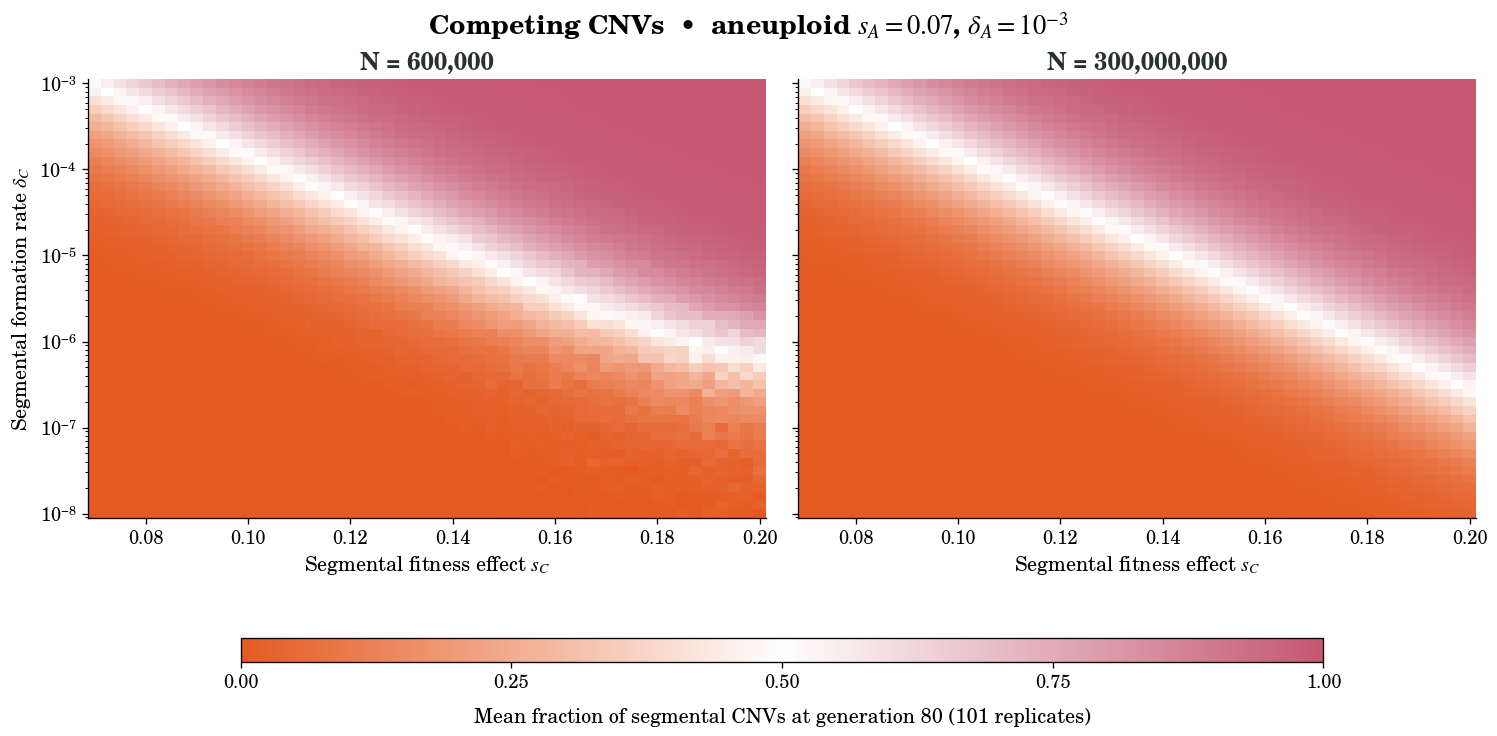

In [13]:
def plot_competition_heatmaps(competition, generation=80):
    generation_index = np.flatnonzero(competition["g"] == generation)
    if len(generation_index) != 1:
        raise ValueError("The requested generation must be in competition['g']")
    s_edges = _cell_edges(competition["s_segmental"])
    delta_edges = _cell_edges(competition["delta_segmental"], logarithmic=True)
    colors = LinearSegmentedColormap.from_list(
        "vitra_segmental_share",
        [(0.0, VITRA_ORANGE), (0.5, "#FFFFFF"), (1.0, VITRA_DUSTY_ROSE)],
    )
    n_populations = len(competition["N"])
    fig, axes = plt.subplots(
        1, n_populations, figsize=(6.2 * n_populations, 6.1),
        sharex=True, sharey=True, layout="constrained", squeeze=False,
    )
    axes = axes.ravel()
    for pop_index, population_size in enumerate(competition["N"]):
        ax = axes[pop_index]
        segmental_share = competition["mean_segmental_cnv_share"][
            generation_index[0], pop_index,
        ].T
        image = ax.pcolormesh(
            s_edges, delta_edges, segmental_share, cmap=colors,
            vmin=0, vmax=1, shading="flat", rasterized=True,
        )
        ax.set_yscale("log")
        ax.set_xlim(s_edges[0], s_edges[-1])
        ax.set_ylim(delta_edges[0], delta_edges[-1])
        ax.set_xlabel(r"Segmental fitness effect $s_C$")
        ax.set_title(f"N = {population_size:,}", fontsize=14, weight="bold",
                     color=VITRA_INK)
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
    axes[0].set_ylabel(r"Segmental formation rate $\delta_C$")
    colorbar = fig.colorbar(
        image, ax=axes.tolist(), orientation="horizontal",
        ticks=np.linspace(0, 1, 5), fraction=0.06, pad=0.13,
        shrink=0.78, aspect=45,
    )
    colorbar.set_label(
        f"Mean fraction of segmental CNVs at generation {generation} "
        f"({competition['n_replicates']} replicates)", labelpad=9,
    )
    baseline_rate = competition["delta_aneuploid"]
    baseline_exponent = int(np.floor(np.log10(baseline_rate)))
    baseline_mantissa = baseline_rate / 10 ** baseline_exponent
    baseline_math = (rf"10^{{{baseline_exponent}}}"
                     if np.isclose(baseline_mantissa, 1)
                     else rf"{baseline_mantissa:.2g}\times10^{{{baseline_exponent}}}")
    fig.suptitle(
        "Competing CNVs  •  "
        + rf"aneuploid $s_A={competition['s_aneuploid']:.2f}$, "
        + rf"$\delta_A={baseline_math}$",
        fontsize=16, weight="bold",
    )
    return fig, axes


fig, axes = plot_competition_heatmaps(competition, generation=80)
plt.show()

A lower-rate segmental CNV can account for a large fraction of CNV cells when its fitness advantage is large enough **and** it appears early enough to expand before generation 80. Orange regions have a smaller segmental share; pink regions have a larger one. These are simulation summaries under the chosen aneuploid scenario above. Changing $s_A$ or $\delta_A$ and rerunning the cells gives a different analysis. The result arrays separately retain the probabilities that the segmental CNV outnumbers the aneuploid, exceeds half the total population, or is the largest of all three genotypes.

## Publication figure: competing CNV routes

This composite figure uses the same three-genotype simulation as above, including aneuploid reversion at rate $\delta_A$. The fixed $s_A=0.07$ is the competition-assay estimate and represents fitness $1.07$ within the revised estimated range of $1.04$–$1.08$; $\delta_A=10^{-3}$ is the fixed high-supply assumption. Orange denotes aneuploids and pink denotes segmental CNVs; population-size headings are black. The left heatmap uses $N=3\times10^8$ for the chemostat, and the right is $N=600{,}000$ (ours). Both heatmaps show the mean fraction of segmental CNVs among CNV cells, $C/(A+C)$, at the final generation (generation 80) across 101 replicate populations. A centered logit color normalization expands differences near fractions 0 and 1 while keeping white at 0.5.

Two parameter settings are outlined in the $N=600{,}000$ map. Case **(1)** uses $s_C=0.08$, $\delta_C=10^{-3}$, where both CNV types rise early. Case **(2)** uses $s_C=0.10$, $\delta_C=10^{-6}$, the lower-supply example. Panel C combines aneuploid and segmental CNV trajectories within one plot for each case through generation 80. Panel D follows the same 501 replicate populations for both cases through generation 300. Trajectory curves show fractions of the whole population. Solid curves are medians; shading spans the central 50% of replicate outcomes (25th–75th percentiles). The PDF export preserves vector text and drawings.


In [14]:
def simulate_competing_trajectories(s_aneuploid, delta_aneuploid,
                                    s_segmental, delta_segmental, N, g,
                                    *, n_replicates=301, seed=2044):
    """Return all-generation frequency paths for both CNV types."""
    if not (s_segmental > s_aneuploid >= 0):
        raise ValueError("Segmental fitness must exceed aneuploid fitness")
    if not (0 <= delta_segmental <= delta_aneuploid and
            delta_aneuploid + delta_segmental <= 1):
        raise ValueError("Segmental formation rate must not exceed the aneuploid rate; rates must sum to at most 1")
    N = int(N)
    if N <= 0:
        raise ValueError("N must be positive")
    max_generation = int(np.max(g))
    aneuploid = np.zeros((n_replicates, max_generation + 1))
    segmental = np.zeros_like(aneuploid)
    count_A = np.zeros(n_replicates, dtype=np.int64)
    count_C = np.zeros(n_replicates, dtype=np.int64)
    rng = np.random.default_rng(seed)
    for t in range(1, max_generation + 1):
        q_A, q_C = competing_offspring_probabilities(
            count_A, count_C, N,
            s_aneuploid, delta_aneuploid, s_segmental, delta_segmental,
        )
        next_A = rng.binomial(N, q_A)
        conditional_C = np.divide(q_C, 1 - q_A,
                                  out=np.zeros_like(q_C), where=(1 - q_A) > 0)
        next_C = rng.binomial(N - next_A, np.clip(conditional_C, 0, 1))
        count_A, count_C = next_A, next_C
        aneuploid[:, t] = count_A / N
        segmental[:, t] = count_C / N
    return aneuploid, segmental

Paper figure: De et al/saaz_figures/saaz_competition_paper_figure.pdf
Selected point: {'N': 600000, 'generation': 80, 'long_generation': 300, 'trajectory_replicates': 501, 'cases': [{'label': '(1)', 's_segmental': 0.08, 'delta_segmental': 0.001, 'grid_mean_segmental_cnv_share': 0.6650587288537151, 'aneuploid_reached_threshold_by_generation': 501, 'segmental_reached_threshold_by_generation': 501, 'segmental_outnumbers_at_long_generation': 501, 'median_segmental_at_long_generation': 0.949535}, {'label': '(2)', 's_segmental': 0.1, 'delta_segmental': 1e-06, 'grid_mean_segmental_cnv_share': 0.006658889515111519, 'aneuploid_reached_threshold_by_generation': 501, 'segmental_reached_threshold_by_generation': 0, 'segmental_outnumbers_at_long_generation': 370, 'median_segmental_at_long_generation': 0.6971466666666667}]}


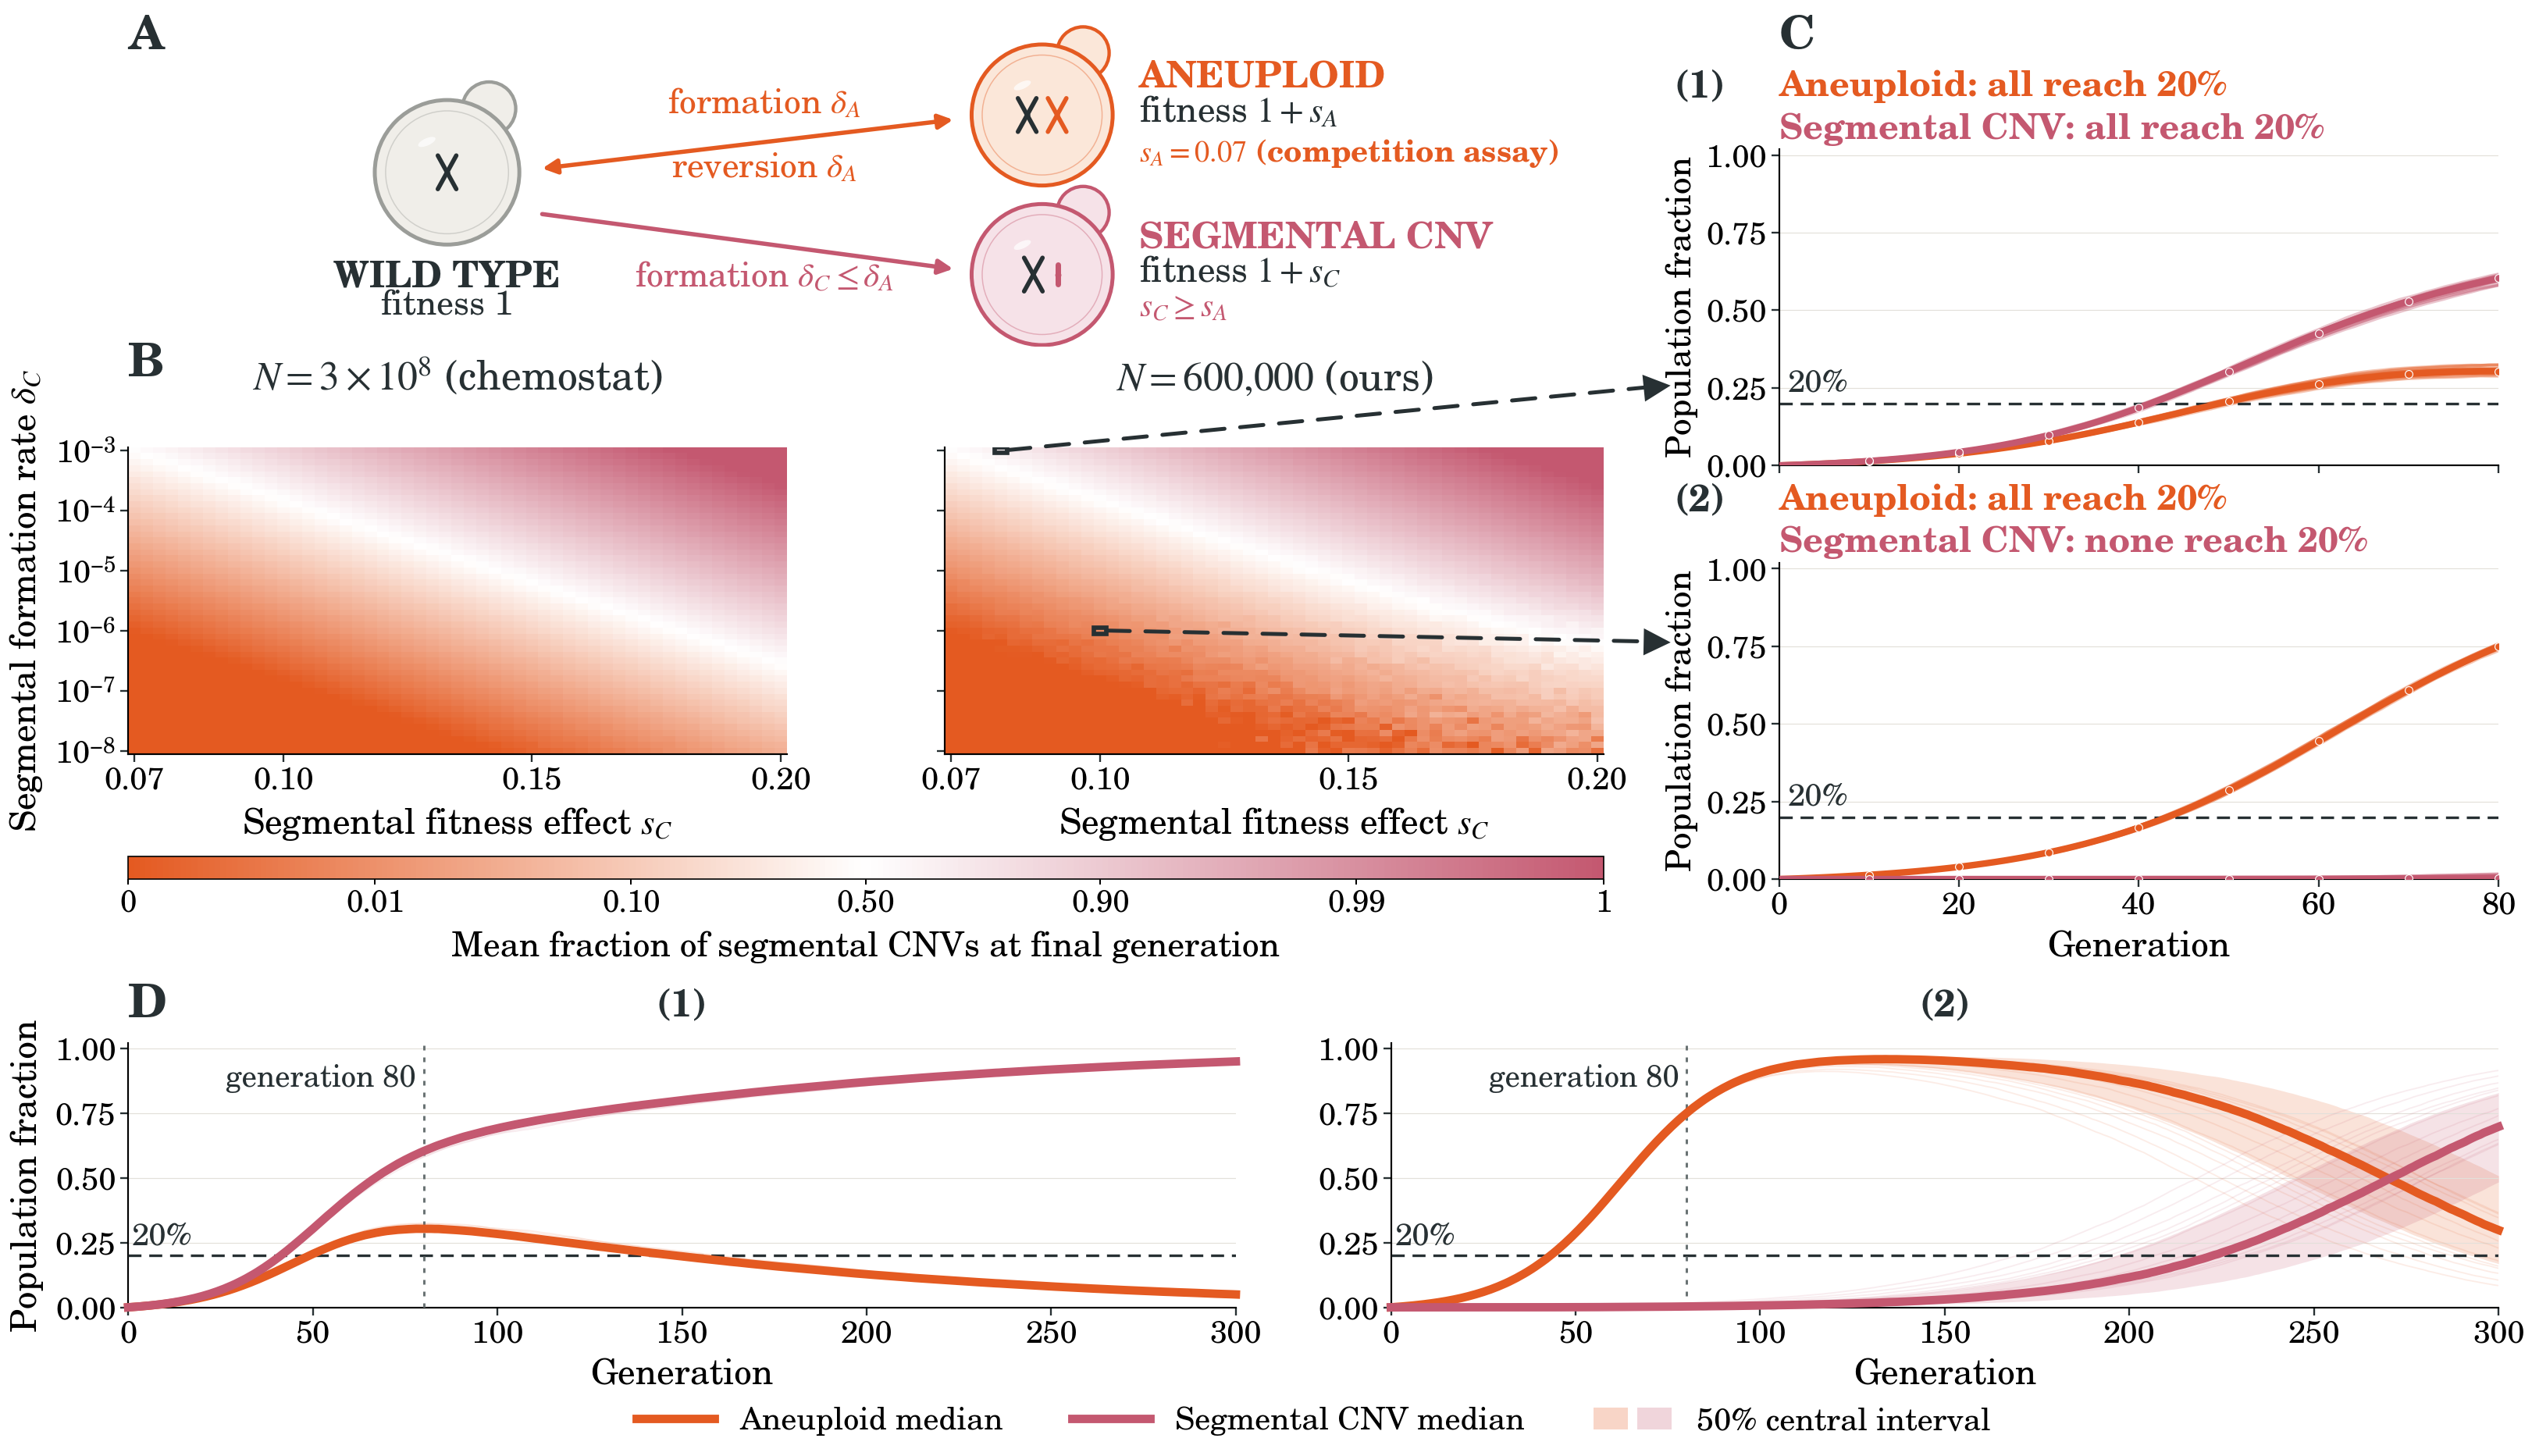

In [15]:
def _draw_chromosome(ax, x, y, *, size=0.13, color=VITRA_INK, linewidth=2.7):
    ax.plot([x - size * 0.55, x + size * 0.55],
            [y - size, y + size], color=color, linewidth=linewidth,
            solid_capstyle="round", zorder=7)
    ax.plot([x - size * 0.55, x + size * 0.55],
            [y + size, y - size], color=color, linewidth=linewidth,
            solid_capstyle="round", zorder=7)
    ax.scatter([x], [y], s=8, color=color, zorder=8)


def _draw_yeast_cell(ax, x, y, *, kind, radius=0.70):
    """Budding yeast cartoon with one representative haploid chromosome."""
    styles = {
        "wt": ("#F0EEE9", "#9B9D99"),
        "aneuploid": ("#FBE7D9", VITRA_ORANGE),
        "segmental": ("#F6E2E8", VITRA_DUSTY_ROSE),
    }
    fill, edge = styles[kind]
    bud = Circle((x + 0.58 * radius, y + 0.88 * radius), 0.37 * radius,
                 facecolor=fill, edgecolor=edge, linewidth=2.6, zorder=2)
    body = Circle((x, y), radius, facecolor=fill, edgecolor=edge,
                  linewidth=3.0, zorder=3)
    ax.add_patch(bud)
    ax.add_patch(body)
    ax.add_patch(Circle((x, y), radius * 0.85, facecolor="none",
                        edgecolor=edge, linewidth=0.9, alpha=0.38, zorder=4))
    ax.add_patch(Ellipse((x - 0.28 * radius, y + 0.42 * radius),
                         0.26 * radius, 0.10 * radius, angle=24,
                         facecolor="white", edgecolor="none", alpha=0.7, zorder=5))
    if kind == "aneuploid":
        _draw_chromosome(ax, x - 0.17, y, size=0.19, linewidth=3.4)
        _draw_chromosome(ax, x + 0.17, y, size=0.19,
                         color=VITRA_ORANGE, linewidth=3.4)
    else:
        _draw_chromosome(ax, x - (0.10 if kind == "segmental" else 0),
                         y, size=0.19, linewidth=3.4)
        if kind == "segmental":
            # A short standalone segment next to the one intact chromosome.
            ax.plot([x + 0.18, x + 0.18], [y - 0.11, y + 0.11],
                    color=VITRA_DUSTY_ROSE, linewidth=4.2,
                    solid_capstyle="round", zorder=9)
            ax.scatter([x + 0.18], [y], s=14, color=VITRA_DUSTY_ROSE,
                       zorder=10)


def plot_publication_competition_figure(competition, *, generation=80,
                                        threshold=0.20, trajectory_replicates=501,
                                        example1_s=0.08, example1_delta=1e-3,
                                        example2_s=0.10, example2_delta=1e-6,
                                        long_generation=300):
    """Return the manuscript figure with two outlined parameter settings."""
    generation_index = np.flatnonzero(competition["g"] == generation)
    if len(generation_index) != 1:
        raise ValueError("generation must occur in competition['g']")
    if long_generation <= generation:
        raise ValueError("long_generation must exceed the heatmap generation")
    time_index = int(generation_index[0])
    work_matches = np.flatnonzero(competition["N"] == 600_000)
    chemostat_matches = np.flatnonzero(competition["N"] == 300_000_000)
    if len(work_matches) != 1 or len(chemostat_matches) != 1:
        raise ValueError("Main figure requires N = 600,000 and N = 300,000,000")
    population_index = int(work_matches[0])
    display_indices = [int(chemostat_matches[0]), population_index]
    surface = competition["mean_segmental_cnv_share"][time_index, population_index]
    s_values = competition["s_segmental"]
    rate_values = competition["delta_segmental"]

    selected_N = int(competition["N"][population_index])
    focus_cases = []
    for label, target_s, target_delta, seed_offset in (
        ("(1)", example1_s, example1_delta, 2081),
        ("(2)", example2_s, example2_delta, 701),
    ):
        s_index = int(np.argmin(np.abs(s_values - target_s)))
        rate_index = int(np.argmin(
            np.abs(np.log(rate_values / target_delta))
        ))
        selected_s = float(s_values[s_index])
        selected_delta = float(rate_values[rate_index])
        aneuploid_paths, segmental_paths = simulate_competing_trajectories(
            competition["s_aneuploid"], competition["delta_aneuploid"],
            selected_s, selected_delta, selected_N, [long_generation],
            n_replicates=trajectory_replicates,
            seed=competition_seed + seed_offset,
        )
        focus_cases.append({
            "label": label,
            "s_index": s_index,
            "rate_index": rate_index,
            "s_segmental": selected_s,
            "delta_segmental": selected_delta,
            "grid_mean_segmental_cnv_share": float(
                surface[s_index, rate_index]
            ),
            "aneuploid_paths": aneuploid_paths,
            "segmental_paths": segmental_paths,
        })

    fig = plt.figure(figsize=(27.0, 15.0), facecolor="white")
    outer_grid = fig.add_gridspec(
        2, 1, height_ratios=[3.3, 1],
        left=0.048, right=0.985, top=0.975, bottom=0.09,
        hspace=0.19,
    )
    top_grid = outer_grid[0].subgridspec(
        1, 2, width_ratios=[2.05, 1], wspace=0.16,
    )
    left_grid = top_grid[0].subgridspec(
        2, 1, height_ratios=[0.44, 0.56], hspace=0.26,
    )
    ax_model = fig.add_subplot(left_grid[0])
    heat_grid = left_grid[1].subgridspec(
        2, 2, height_ratios=[1, 0.075], hspace=0.62, wspace=0.24,
    )
    heat_axes = [fig.add_subplot(heat_grid[0, 0]),
                 fig.add_subplot(heat_grid[0, 1])]
    color_axis = fig.add_subplot(heat_grid[1, :])
    trajectory_grid = top_grid[1].subgridspec(
        3, 1, height_ratios=[0.14, 1, 1], hspace=0.43,
    )
    ax_trajectory_header = fig.add_subplot(trajectory_grid[0])
    trajectory_axes = [fig.add_subplot(trajectory_grid[1]),
                       fig.add_subplot(trajectory_grid[2])]
    long_grid = outer_grid[1].subgridspec(1, 2, wspace=0.14)
    long_axes = [fig.add_subplot(long_grid[0, 0]),
                 fig.add_subplot(long_grid[0, 1])]
    for ax_long in long_axes:
        long_box = ax_long.get_position()
        ax_long.set_position([long_box.x0, long_box.y0 - 0.040,
                              long_box.width, long_box.height])

    # Panel A: budding yeast and chromosome-level differences.
    ax_model.set_xlim(0, 14.0)
    ax_model.set_ylim(0, 3.85)
    ax_model.set_aspect("equal")
    ax_model.axis("off")
    panel_letter_x = long_axes[0].get_position().x0
    top_heading_y = outer_grid[0].get_position(fig).y1 - 0.005
    fig.text(panel_letter_x, top_heading_y, "A", fontsize=36,
             weight="bold", va="top", color=VITRA_INK)
    _draw_yeast_cell(ax_model, 2.25, 1.98, kind="wt", radius=0.82)
    _draw_yeast_cell(ax_model, 9.00, 2.63, kind="aneuploid", radius=0.80)
    _draw_yeast_cell(ax_model, 9.00, 0.82, kind="segmental", radius=0.80)
    ax_model.add_patch(FancyArrowPatch(
        (3.30, 2.02), (8.02, 2.58), arrowstyle="<|-|>",
        mutation_scale=23, linewidth=3.3, color=VITRA_ORANGE, zorder=1,
    ))
    ax_model.add_patch(FancyArrowPatch(
        (3.30, 1.51), (8.02, 0.88), arrowstyle="-|>",
        mutation_scale=23, linewidth=3.3, color=VITRA_DUSTY_ROSE, zorder=1,
    ))
    ax_model.text(2.25, 0.68, "WILD TYPE", fontsize=28, weight="bold",
                  ha="center", color=VITRA_INK)
    ax_model.text(2.25, 0.36, "fitness 1", fontsize=26,
                  ha="center", color=VITRA_INK)
    ax_model.text(5.85, 2.65, r"formation $\delta_A$", fontsize=26,
                  ha="center", color=VITRA_ORANGE)
    ax_model.text(5.85, 1.92, r"reversion $\delta_A$", fontsize=26,
                  ha="center", color=VITRA_ORANGE)
    ax_model.text(5.85, 0.68, r"formation $\delta_C \leq \delta_A$", fontsize=26,
                  ha="center", color=VITRA_DUSTY_ROSE)
    ax_model.text(10.10, 2.95, "ANEUPLOID", fontsize=28,
                  weight="bold", color=VITRA_ORANGE)
    ax_model.text(10.10, 2.55, r"fitness $1+s_A$", fontsize=27,
                  color=VITRA_INK)
    ax_model.text(10.10, 2.10,
                  r"$s_A=0.07$ (competition assay)", fontsize=23,
                  weight="bold", color=VITRA_ORANGE)
    ax_model.text(10.10, 1.12, "SEGMENTAL CNV", fontsize=28,
                  weight="bold", color=VITRA_DUSTY_ROSE)
    ax_model.text(10.10, 0.73, r"fitness $1+s_C$", fontsize=27,
                  color=VITRA_INK)
    ax_model.text(10.10, 0.34, r"$s_C \geq s_A$", fontsize=25,
                  weight="bold", color=VITRA_DUSTY_ROSE)

    # Panel B: matched orange-white-pink CNV-share maps.
    map_colors = LinearSegmentedColormap.from_list(
        "vitra_orange_white_pink",
        [(0.0, VITRA_ORANGE), (0.5, "#FFFFFF"),
         (1.0, VITRA_DUSTY_ROSE)],
    )
    from matplotlib.colors import FuncNorm
    color_floor = 1e-3

    def logit_forward(values):
        clipped = np.clip(np.asarray(values, dtype=float),
                          color_floor, 1 - color_floor)
        return np.log(clipped / (1 - clipped))

    def logit_inverse(values):
        values = np.asarray(values, dtype=float)
        return 1 / (1 + np.exp(-values))

    color_norm = FuncNorm(
        (logit_forward, logit_inverse), vmin=0, vmax=1,
    )
    s_edges = _cell_edges(s_values)
    rate_edges = _cell_edges(rate_values, logarithmic=True)
    image = None
    display_titles = [r"$N=3\times10^8$ (chemostat)",
                      r"$N=600{,}000$ (ours)"]
    for ax, source_index, display_title in zip(
        heat_axes, display_indices, display_titles,
    ):
        segmental_share = competition["mean_segmental_cnv_share"][
            time_index, source_index,
        ].T
        image = ax.pcolormesh(
            s_edges, rate_edges, segmental_share, cmap=map_colors,
            norm=color_norm, shading="flat", rasterized=True,
        )
        ax.set_yscale("log")
        ax.set_xlim(s_edges[0], s_edges[-1])
        ax.set_ylim(rate_edges[0], rate_edges[-1])
        s_ticks = np.unique(np.r_[s_values[0],
                                  np.arange(0.10, s_values[-1] + 0.001, 0.05)])
        ax.set_xticks(s_ticks)
        ax.set_xlim(s_edges[0], s_edges[-1])
        ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
        ax.tick_params(axis="both", labelsize=24, length=6, width=1.4,
                       color=VITRA_INK)
        ax.spines["left"].set_linewidth(1.3)
        ax.spines["bottom"].set_linewidth(1.3)
        ax.set_xlabel(r"Segmental fitness effect $s_C$", fontsize=27,
                      labelpad=8)
        ax.set_title(display_title, fontsize=31,
                     color=VITRA_INK, pad=44)
    heat_axes[0].set_ylabel(r"Segmental formation rate $\delta_C$",
                            fontsize=27, labelpad=8)
    heat_axes[1].tick_params(labelleft=False)
    colorbar = fig.colorbar(
        image, cax=color_axis, orientation="horizontal",
        ticks=[0, 0.01, 0.10, 0.50, 0.90, 0.99, 1],
    )
    colorbar.ax.tick_params(labelsize=23, width=1.2, length=4)
    colorbar.ax.set_xticklabels(
        ["0", "0.01", "0.10", "0.50", "0.90", "0.99", "1"]
    )
    colorbar.outline.set_linewidth(1.0)
    colorbar.set_label(
        "Mean fraction of segmental CNVs at final generation",
        fontsize=26, labelpad=10,
    )
    b_heading_y = heat_axes[0].get_position().y1 + 0.075
    fig.text(panel_letter_x, b_heading_y, "B", fontsize=36,
             weight="bold", color=VITRA_INK, va="top")

    # Outline both parameter cells in the N=600,000 (ours) map.
    selected_ax = heat_axes[1]
    for case in focus_cases:
        s_index = case["s_index"]
        rate_index = case["rate_index"]
        selected_ax.add_patch(Rectangle(
            (s_edges[s_index], rate_edges[rate_index]),
            s_edges[s_index + 1] - s_edges[s_index],
            rate_edges[rate_index + 1] - rate_edges[rate_index],
            fill=False, edgecolor=VITRA_INK, linewidth=3.4, zorder=10,
        ))

    # Panel C: each case combines aneuploid and segmental trajectories.
    times = np.arange(generation + 1)
    sampled_generations = np.asarray(competition["g"], dtype=int)
    sampled_generations = sampled_generations[
        sampled_generations <= generation
    ]
    trace_rng = np.random.default_rng(181)
    trace_indices = trace_rng.choice(
        trajectory_replicates, size=min(20, trajectory_replicates),
        replace=False,
    )
    for ax, case in zip(trajectory_axes, focus_cases):
        short_A = case["aneuploid_paths"][:, :generation + 1]
        short_C = case["segmental_paths"][:, :generation + 1]
        for paths, color in (
            (short_A, VITRA_ORANGE),
            (short_C, VITRA_DUSTY_ROSE),
        ):
            for row in paths[trace_indices]:
                ax.plot(times, row, color=color, alpha=0.34,
                        linewidth=2.3, zorder=2)
            lower, upper = np.quantile(paths, [0.25, 0.75], axis=0)
            ax.fill_between(times, lower, upper, color=color,
                            alpha=0.20, linewidth=0, zorder=1)
            median_path = np.median(paths, axis=0)
            ax.plot(times, median_path, color=color,
                    linewidth=5.0, zorder=5)
            ax.scatter(
                sampled_generations, median_path[sampled_generations],
                s=35, color=color, edgecolor="white", linewidth=0.7,
                zorder=6,
            )
        crossed_A = int(np.any(short_A >= threshold, axis=1).sum())
        crossed_C = int(np.any(short_C >= threshold, axis=1).sum())
        def reach_text(count):
            if count == trajectory_replicates:
                return "all reach 20%"
            if count == 0:
                return "none reach 20%"
            return f"{count}/{trajectory_replicates} reach 20%"
        ax.text(-0.145, 1.25, case["label"], transform=ax.transAxes,
                fontsize=29, weight="bold", color=VITRA_INK,
                ha="left", va="top", clip_on=False)
        ax.text(0.0, 1.25,
                f"Aneuploid: {reach_text(crossed_A)}",
                transform=ax.transAxes, fontsize=27, weight="bold",
                color=VITRA_ORANGE, ha="left", va="top", clip_on=False)
        ax.text(0.0, 1.115,
                f"Segmental CNV: {reach_text(crossed_C)}",
                transform=ax.transAxes, fontsize=27, weight="bold",
                color=VITRA_DUSTY_ROSE, ha="left", va="top", clip_on=False)
        ax.axhline(threshold, color=VITRA_INK, linewidth=2.0,
                   linestyle=(0, (5, 3)), zorder=3)
        ax.text(1.0, threshold + 0.018, "20%", ha="left", va="bottom",
                fontsize=24, color=VITRA_INK)
        ax.set_xlim(0, generation)
        ax.set_ylim(0, 1.02)
        ax.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
        ax.set_xticks([0, 20, 40, 60, 80])
        ax.tick_params(axis="both", labelsize=24, length=6, width=1.4,
                       color=VITRA_INK)
        ax.spines["left"].set_linewidth(1.3)
        ax.spines["bottom"].set_linewidth(1.3)
        ax.grid(axis="y", color="#E3E0DA", linewidth=0.7, zorder=0)
        ax.set_ylabel("Population fraction", fontsize=26, labelpad=6)
    trajectory_axes[0].tick_params(labelbottom=False)
    trajectory_axes[1].set_xlabel("Generation", fontsize=27, labelpad=8)
    ax_trajectory_header.axis("off")
    fig.text(ax_trajectory_header.get_position().x0, top_heading_y,
             "C", fontsize=36, weight="bold", color=VITRA_INK, va="top")

    # Draw dashed shafts through the arrowhead centers, then place identical
    # rotated triangle heads over their endpoints so no dash-to-head gap forms.
    from matplotlib.markers import MarkerStyle
    from matplotlib.transforms import Affine2D
    for case, destination_ax, destination_height in zip(
        focus_cases, trajectory_axes, (0.25, 0.75)
    ):
        s_index = case["s_index"]
        rate_index = case["rate_index"]
        source_xy = (
            s_edges[s_index + 1],
            np.sqrt(rate_edges[rate_index] * rate_edges[rate_index + 1]),
        )
        destination_xy = (-0.17, destination_height)
        fig.add_artist(ConnectionPatch(
            xyA=source_xy,
            coordsA=selected_ax.transData,
            xyB=destination_xy,
            coordsB=destination_ax.transAxes,
            color=VITRA_INK, linewidth=3.0, linestyle=(0, (6, 4)),
            arrowstyle="-",
            connectionstyle="arc3,rad=0", zorder=8, clip_on=False,
        ))
        source_display = selected_ax.transData.transform(source_xy)
        destination_display = destination_ax.transAxes.transform(
            destination_xy
        )
        arrow_angle = np.degrees(np.arctan2(
            destination_display[1] - source_display[1],
            destination_display[0] - source_display[0],
        ))
        arrow_marker = MarkerStyle(">").transformed(
            Affine2D().rotate_deg(arrow_angle)
        )
        destination_ax.scatter(
            [destination_xy[0]], [destination_xy[1]],
            transform=destination_ax.transAxes, marker=arrow_marker,
            s=430, facecolor=VITRA_INK, edgecolor=VITRA_INK,
            linewidth=0, zorder=9, clip_on=False,
        )

    # Panel D: continue both cases through the long time horizon.
    long_times = np.arange(long_generation + 1)
    for ax_long, case in zip(long_axes, focus_cases):
        for paths, color in (
            (case["aneuploid_paths"], VITRA_ORANGE),
            (case["segmental_paths"], VITRA_DUSTY_ROSE),
        ):
            for row in paths[trace_indices[:12]]:
                ax_long.plot(long_times, row, color=color, alpha=0.11,
                             linewidth=1.1, zorder=2)
            lower, upper = np.quantile(paths, [0.25, 0.75], axis=0)
            ax_long.fill_between(long_times, lower, upper, color=color,
                                 alpha=0.17, linewidth=0, zorder=1)
            ax_long.plot(long_times, np.median(paths, axis=0), color=color,
                         linewidth=6.5, zorder=6, clip_on=False)
        ax_long.axhline(threshold, color=VITRA_INK, linewidth=2.0,
                        linestyle=(0, (5, 3)), zorder=3)
        ax_long.text(1.0, threshold + 0.018, "20%", ha="left", va="bottom",
                     fontsize=24, color=VITRA_INK)
        ax_long.axvline(generation, color="#6A7374", linewidth=1.8,
                        linestyle=(0, (2, 3)), zorder=3)
        ax_long.text(generation - 2, 0.94, f"generation {generation}",
                     fontsize=23, color=VITRA_INK, va="top", ha="right")
        ax_long.text(0.5, 1.07, case["label"], transform=ax_long.transAxes,
                     fontsize=29, weight="bold", color=VITRA_INK,
                     ha="center", va="bottom", clip_on=False)
        ax_long.set_xlim(0, long_generation)
        ax_long.set_ylim(0, 1.02)
        ax_long.set_xticks([0, 50, 100, 150, 200, 250, 300])
        ax_long.set_yticks([0, 0.25, 0.50, 0.75, 1.00])
        ax_long.tick_params(axis="both", labelsize=24, length=6, width=1.4,
                            color=VITRA_INK)
        ax_long.spines["left"].set_linewidth(1.3)
        ax_long.spines["bottom"].set_linewidth(1.3)
        ax_long.grid(axis="y", color="#E3E0DA", linewidth=0.7, zorder=0)
        ax_long.set_xlabel("Generation", fontsize=27, labelpad=8)
    long_axes[0].set_ylabel("Population fraction", fontsize=27, labelpad=9)
    fig.text(panel_letter_x, long_axes[0].get_position().y1 + 0.043,
             "D", fontsize=36, weight="bold", color=VITRA_INK, va="top")
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    from matplotlib.legend_handler import HandlerTuple
    long_axes[0].legend(
        handles=[Line2D([], [], color=VITRA_ORANGE, linewidth=6.5),
                 Line2D([], [], color=VITRA_DUSTY_ROSE, linewidth=6.5),
                 (Patch(facecolor=VITRA_ORANGE, alpha=0.25),
                  Patch(facecolor=VITRA_DUSTY_ROSE, alpha=0.25))],
        labels=["Aneuploid median", "Segmental CNV median",
                "50% central interval"],
        handler_map={tuple: HandlerTuple(ndivide=None, pad=0.3)},
        loc="upper center", bbox_to_anchor=(1.07, -0.27),
        ncol=3, frameon=False, fontsize=24, handlelength=2.5,
        columnspacing=2.2,
    )

    selected_cases = []
    for case in focus_cases:
        paths_A = case["aneuploid_paths"]
        paths_C = case["segmental_paths"]
        selected_cases.append({
            "label": case["label"],
            "s_segmental": case["s_segmental"],
            "delta_segmental": case["delta_segmental"],
            "grid_mean_segmental_cnv_share":
                case["grid_mean_segmental_cnv_share"],
            "aneuploid_reached_threshold_by_generation": int(np.any(
                paths_A[:, :generation + 1] >= threshold, axis=1).sum()),
            "segmental_reached_threshold_by_generation": int(np.any(
                paths_C[:, :generation + 1] >= threshold, axis=1).sum()),
            "segmental_outnumbers_at_long_generation": int((
                paths_C[:, long_generation] > paths_A[:, long_generation]
            ).sum()),
            "median_segmental_at_long_generation": float(np.median(
                paths_C[:, long_generation]
            )),
        })
    selected = {
        "N": selected_N,
        "generation": generation,
        "long_generation": long_generation,
        "trajectory_replicates": trajectory_replicates,
        "cases": selected_cases,
    }
    return fig, selected


paper_fig, selected_point = plot_publication_competition_figure(competition)
figure_dir = Path("saaz_figures")
if not Path("saaz_model.ipynb").exists() and Path("De et al/saaz_model.ipynb").exists():
    figure_dir = Path("De et al/saaz_figures")
figure_dir.mkdir(parents=True, exist_ok=True)
figure_pdf = figure_dir / "saaz_competition_paper_figure.pdf"
figure_png = figure_dir / "saaz_competition_paper_figure.png"
paper_fig.savefig(figure_pdf, bbox_inches="tight", pad_inches=0.10)
paper_fig.savefig(figure_png, dpi=300, bbox_inches="tight", pad_inches=0.10)
print("Paper figure:", figure_pdf)
print("Selected point:", selected_point)
plt.show()


**Draft figure legend.** (A) Haploid wild type gives rise to aneuploid or segmental CNV genotypes. In the model, aneuploidy reverts to wild type at the same assumed rate as it forms, $\delta_A$; segmental CNVs do not revert. The segmental formation rate is equal to or lower than the aneuploid formation rate across the grid. (B) Mean fraction of CNV cells that are segmental, $C/(A+C)$, at generation 80, averaged across 101 independent replicate populations per grid cell. Orange indicates aneuploid predominance among CNV cells, pink indicates segmental predominance, and white indicates a roughly equal split. The outlined cell in the $N=600{,}000$ (ours) panel marks $s_C=0.10$ and $\delta_C=10^{-6}$, which are used in C. The fixed $s_A=0.07$ represents fitness $1.07$ within the revised estimated aneuploid range of $1.04$–$1.08$; $\delta_A=10^{-3}$ is the fixed high-supply setting motivated by [Kohanovski et al. (2024)](https://academic.oup.com/mbe/article/41/3/msae052/7617296), whose estimate came from a different yeast ploidy and stress condition. Neither parameter is directly fitted to this experiment. (C) The aneuploid and segmental trajectories from the same 501 replicate populations through generation 80. Faint lines show individual populations, the thick line shows their median, shading spans the central 50% of simulated populations (25th–75th percentiles), and the dashed line marks a 20% frequency reference. (D) The **same trajectories** extended to generation 300. The vertical line marks generation 80. Aneuploid cells dominate early, while rare segmental lineages expand later in a subset of populations; the median is shown for each type. Panel B divides segmental cells by all CNV cells; panels C and D divide each mutant type by all cells.

## Supplementary figure: population-size and endpoint sensitivity

The combined supplementary figure shows the same six population sizes in columns and the two final generations in rows: generation 80 on top and generation 300 below. Both rows use the same high-resolution segmental parameter grid, fixed aneuploid parameters, aneuploid reversion rule, orange–white–pink scale, and 101 replicates per heatmap cell. Each color is the mean segmental fraction among CNV cells, $C/(A+C)$, at the indicated final generation.

Combined supplementary figure: De et al/saaz_figures/saaz_competition_supplementary_population_sizes.pdf


<cell 29>:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


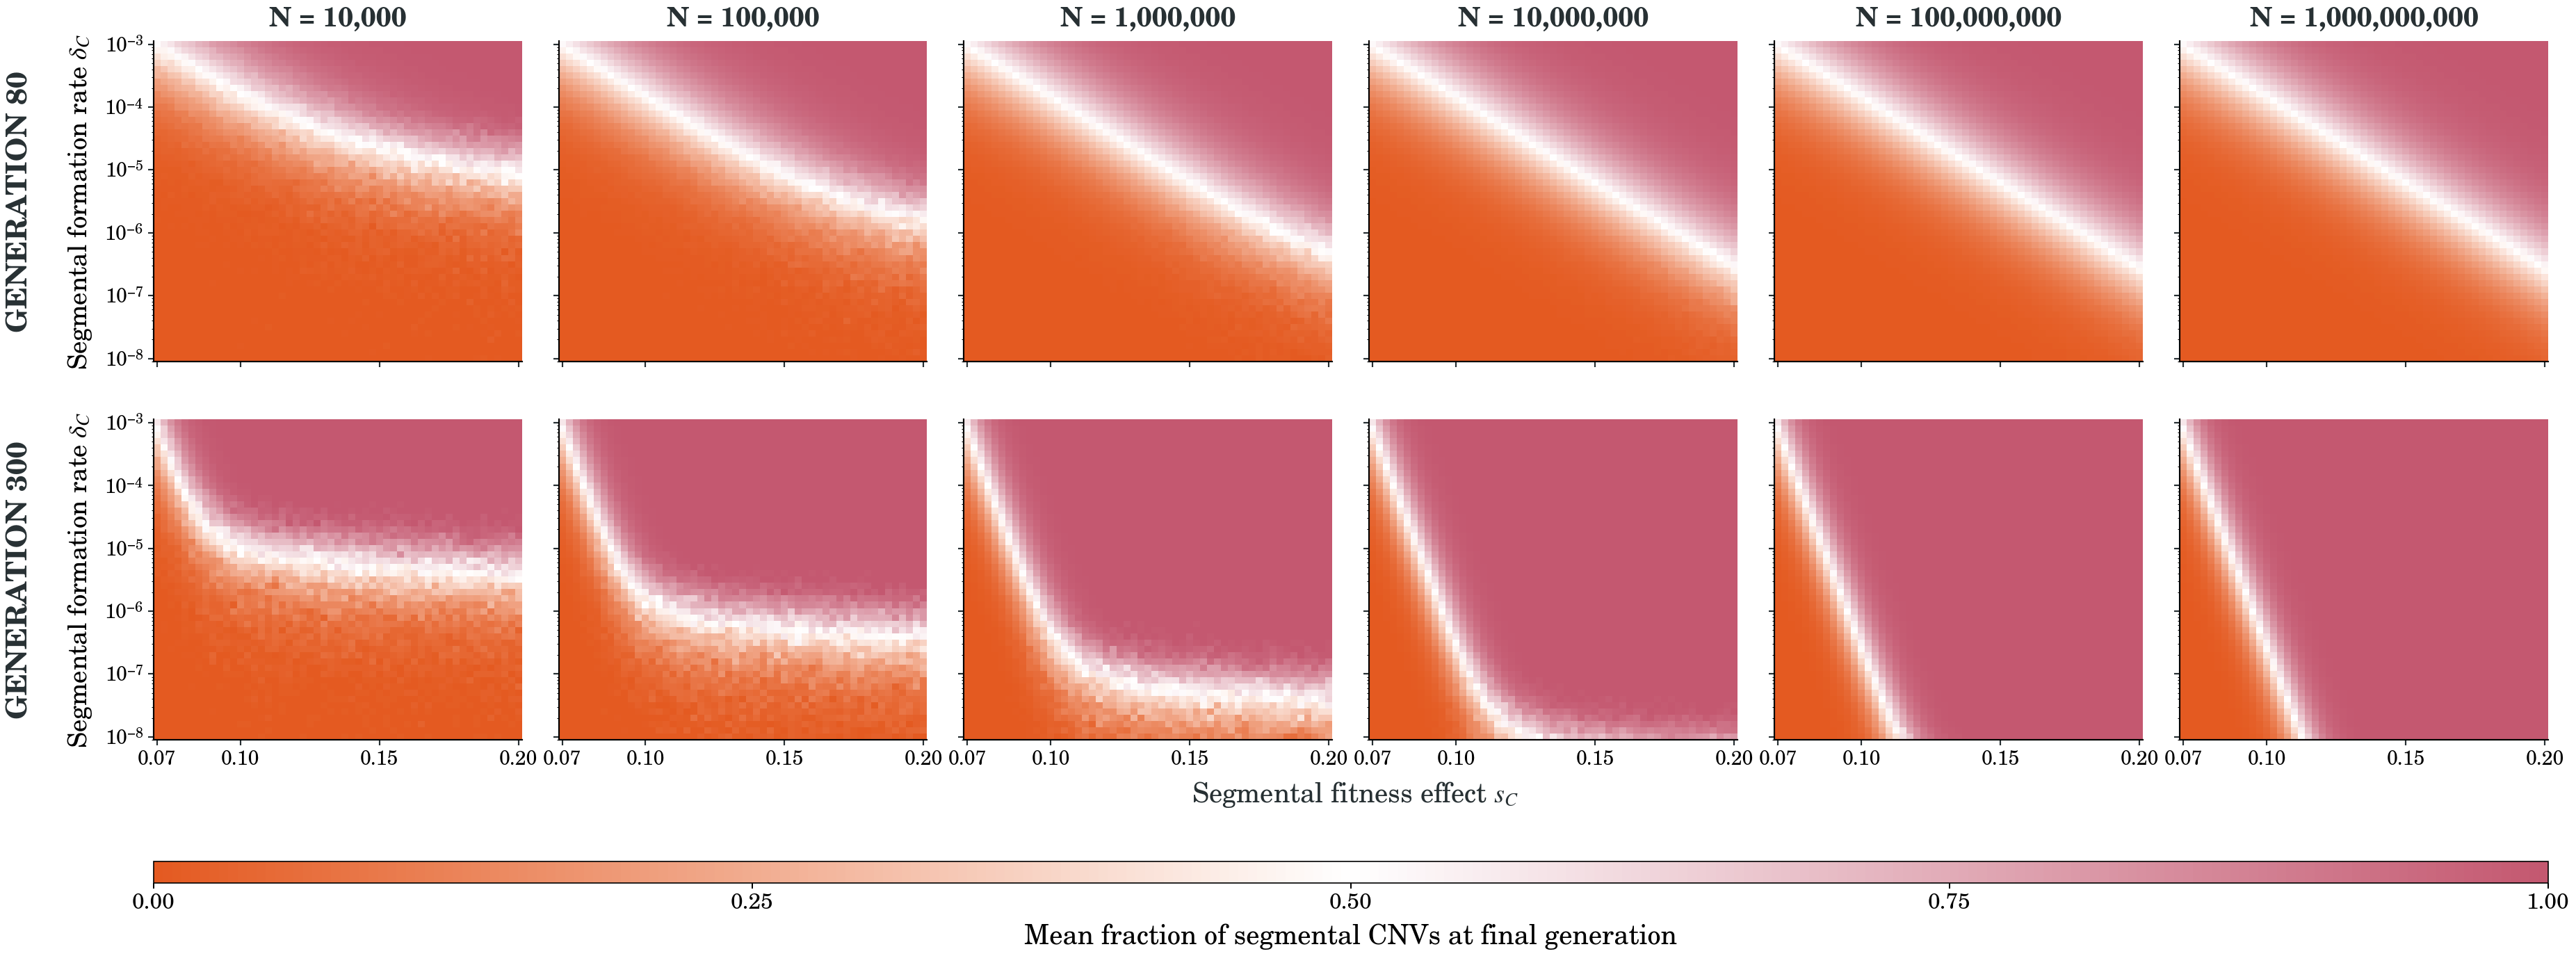

In [16]:
supplementary_N = np.array([
    10_000, 100_000, 1_000_000,
    10_000_000, 100_000_000, 1_000_000_000,
], dtype=np.int64)
supplementary_generations = np.array([80, 300])
supplementary_competition = simulate_competing_cnv_grid(
    aneuploid_s, aneuploid_delta,
    segmental_s, segmental_delta,
    supplementary_N, supplementary_generations,
    n_replicates=n_replicates, seed=competition_seed + 101,
)


def plot_supplementary_population_by_generation(competition,
                                                 generations=(80, 300)):
    """Rows are final generations; columns are population sizes."""
    if len(competition["N"]) != 6:
        raise ValueError("Expected six population sizes")
    generation_indices = []
    for generation in generations:
        matches = np.flatnonzero(competition["g"] == generation)
        if len(matches) != 1:
            raise ValueError(f"Generation {generation} is unavailable")
        generation_indices.append(int(matches[0]))

    s_values = competition["s_segmental"]
    delta_values = competition["delta_segmental"]
    s_edges = _cell_edges(s_values)
    delta_edges = _cell_edges(delta_values, logarithmic=True)
    colors = LinearSegmentedColormap.from_list(
        "vitra_supplementary_cnv_share",
        [(0.0, VITRA_ORANGE), (0.5, "#FFFFFF"),
         (1.0, VITRA_DUSTY_ROSE)],
    )

    fig = plt.figure(figsize=(32.0, 11.8), facecolor="white")
    grid = fig.add_gridspec(
        2, 6,
        left=0.095, right=0.992, top=0.93, bottom=0.22,
        hspace=0.18, wspace=0.10,
    )
    axes = np.empty((2, 6), dtype=object)
    image = None
    s_ticks = np.unique(np.r_[s_values[0],
                              np.arange(0.10, s_values[-1] + 0.001, 0.05)])

    for row, (generation, generation_index) in enumerate(
        zip(generations, generation_indices)
    ):
        for column, population_size in enumerate(competition["N"]):
            ax = fig.add_subplot(grid[row, column])
            axes[row, column] = ax
            share = competition["mean_segmental_cnv_share"][
                generation_index, column,
            ].T
            image = ax.pcolormesh(
                s_edges, delta_edges, share,
                cmap=colors, vmin=0, vmax=1,
                shading="flat", rasterized=True,
            )
            ax.set_yscale("log")
            ax.set_xlim(s_edges[0], s_edges[-1])
            ax.set_ylim(delta_edges[0], delta_edges[-1])
            ax.set_xticks(s_ticks)
            ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))
            ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
            ax.tick_params(axis="both", labelsize=17, length=5, width=1.3,
                           color=VITRA_INK)
            ax.spines["left"].set_linewidth(1.3)
            ax.spines["bottom"].set_linewidth(1.3)
            if row == 0:
                ax.set_title(f"N = {population_size:,}", fontsize=23,
                             weight="bold", color=VITRA_INK, pad=13)
                ax.tick_params(labelbottom=False)
            if column == 0:
                ax.set_ylabel(r"Segmental formation rate $\delta_C$",
                              fontsize=22, labelpad=9)
            else:
                ax.tick_params(labelleft=False)

    fig.canvas.draw()
    for row, generation in enumerate(generations):
        position = axes[row, 0].get_position()
        fig.text(
            0.045, 0.5 * (position.y0 + position.y1),
            f"GENERATION {generation}",
            rotation=90, ha="center", va="center",
            fontsize=25, weight="bold", color=VITRA_INK,
        )

    fig.text(0.545, 0.165, r"Segmental fitness effect $s_C$",
             ha="center", va="center", fontsize=23, color=VITRA_INK)
    color_axis = fig.add_axes([0.095, 0.075, 0.897, 0.022])
    colorbar = fig.colorbar(
        image, cax=color_axis, orientation="horizontal",
        ticks=[0, 0.25, 0.5, 0.75, 1],
    )
    colorbar.ax.tick_params(labelsize=19, width=1.2, length=5)
    colorbar.outline.set_linewidth(1.0)
    colorbar.set_label(
        "Mean fraction of segmental CNVs at final generation",
        fontsize=23, labelpad=9,
    )
    return fig, axes


supplementary_fig, supplementary_axes = plot_supplementary_population_by_generation(
    supplementary_competition,
)
figure_dir = Path("saaz_figures")
if not Path("saaz_model.ipynb").exists() and Path("De et al/saaz_model.ipynb").exists():
    figure_dir = Path("De et al/saaz_figures")
figure_dir.mkdir(parents=True, exist_ok=True)
supplementary_pdf = figure_dir / "saaz_competition_supplementary_population_sizes.pdf"
supplementary_png = figure_dir / "saaz_competition_supplementary_population_sizes.png"
supplementary_fig.savefig(supplementary_pdf, bbox_inches="tight", pad_inches=0.10)
supplementary_fig.savefig(supplementary_png, dpi=300, bbox_inches="tight", pad_inches=0.10)
for obsolete in (
    figure_dir / "saaz_competition_supplementary_population_sizes_gen300.pdf",
    figure_dir / "saaz_competition_supplementary_population_sizes_gen300.png",
):
    if obsolete.exists():
        obsolete.unlink()
print("Combined supplementary figure:", supplementary_pdf)
plt.show()

## Focused comparison: three population sizes across final generations

This focused heatmap figure compares $N=100{,}000$, $N=600{,}000$ (ours), and $N=3\times10^8$ (chemostat) in columns at final generations 80, 200, and 300 in rows. It uses the same high-resolution segmental parameter grid, fixed aneuploid parameters, reversion rule, 101 replicates, and seed as the main analysis. Colors report the mean fraction of segmental CNVs among CNV cells, $C/(A+C)$, at each row’s final generation. A centered logit normalization, clipped at 0.001 and 0.999, expands visual differences near zero and one while preserving white at 0.5.


Focused generation comparison: De et al/saaz_figures/saaz_competition_three_populations_by_generation.pdf


<cell 31>:140: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


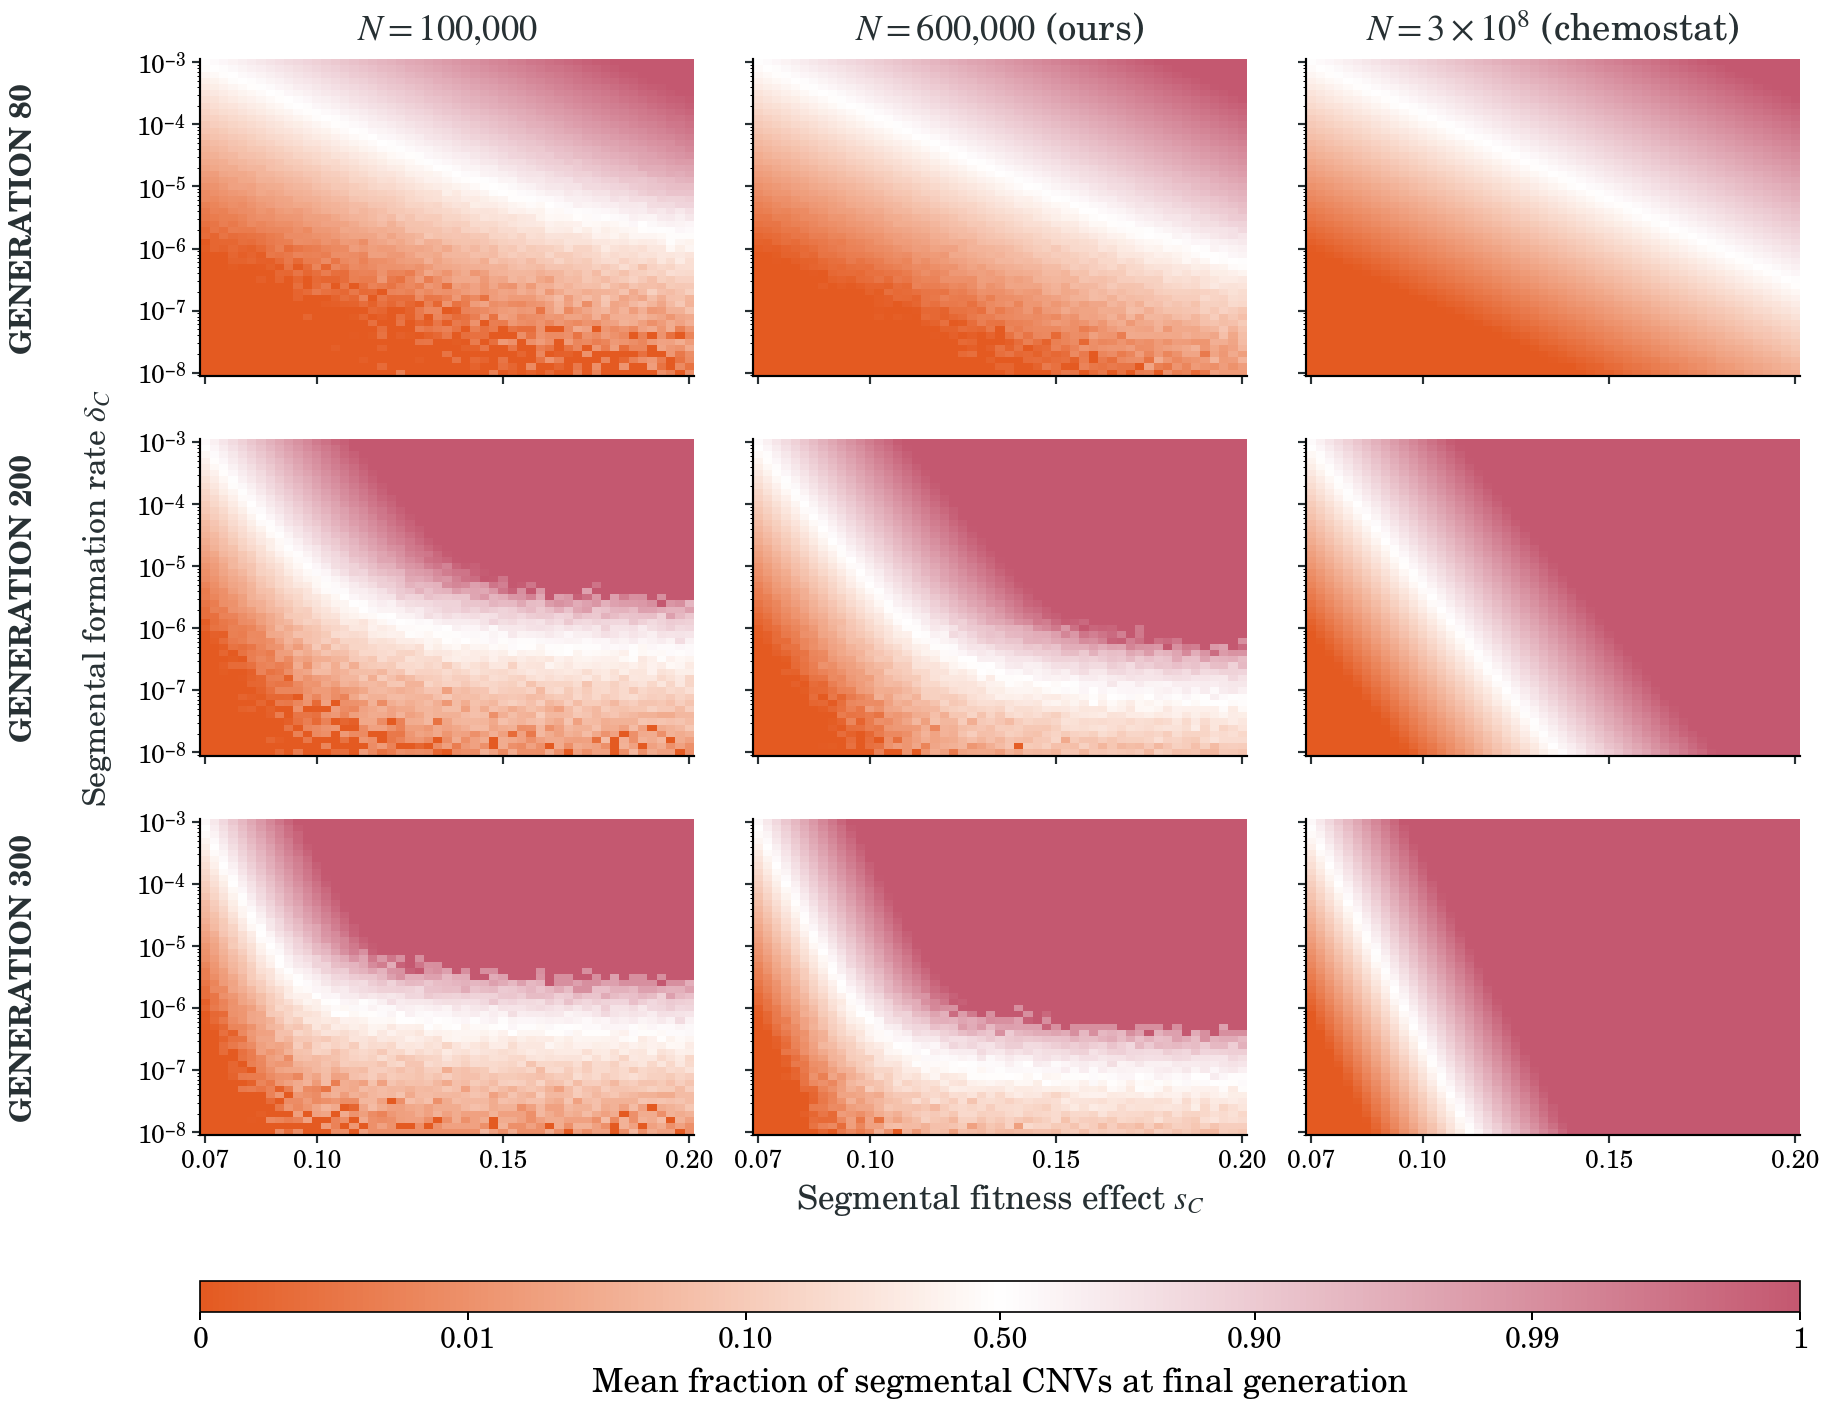

In [17]:
focused_N = np.array([100_000, 600_000, 300_000_000], dtype=np.int64)
focused_generations = np.array([80, 200, 300])
from matplotlib.colors import FuncNorm
focused_competition = simulate_competing_cnv_grid(
    aneuploid_s, aneuploid_delta,
    segmental_s, segmental_delta,
    focused_N, focused_generations,
    n_replicates=n_replicates, seed=competition_seed,
)


def plot_focused_population_by_generation(competition,
                                          generations=(80, 200, 300)):
    """Rows are final generations; columns are three population sizes."""
    if len(competition["N"]) != 3:
        raise ValueError("Expected three population sizes")
    generation_indices = []
    for generation in generations:
        matches = np.flatnonzero(competition["g"] == generation)
        if len(matches) != 1:
            raise ValueError(f"Generation {generation} is unavailable")
        generation_indices.append(int(matches[0]))

    s_values = competition["s_segmental"]
    delta_values = competition["delta_segmental"]
    s_edges = _cell_edges(s_values)
    delta_edges = _cell_edges(delta_values, logarithmic=True)
    colors = LinearSegmentedColormap.from_list(
        "vitra_focused_cnv_share",
        [(0.0, VITRA_ORANGE), (0.5, "#FFFFFF"),
         (1.0, VITRA_DUSTY_ROSE)],
    )
    color_floor = 1e-3
    def logit_forward(values):
        clipped = np.clip(np.asarray(values, dtype=float),
                          color_floor, 1 - color_floor)
        return np.log(clipped / (1 - clipped))
    def logit_inverse(values):
        values = np.asarray(values, dtype=float)
        return 1 / (1 + np.exp(-values))
    color_norm = FuncNorm(
        (logit_forward, logit_inverse), vmin=0, vmax=1,
    )
    column_titles = [r"$N=100{,}000$",
                     r"$N=600{,}000$ (ours)",
                     r"$N=3\times10^8$ (chemostat)"]

    fig = plt.figure(figsize=(15.5, 11.8), facecolor="white")
    grid = fig.add_gridspec(
        3, 3,
        left=0.13, right=0.99, top=0.95, bottom=0.19,
        hspace=0.20, wspace=0.12,
    )
    axes = np.empty((3, 3), dtype=object)
    image = None
    s_ticks = np.unique(np.r_[s_values[0],
                              np.arange(0.10, s_values[-1] + 0.001, 0.05)])

    for row, (generation, generation_index) in enumerate(
        zip(generations, generation_indices)
    ):
        for column, title in enumerate(column_titles):
            ax = fig.add_subplot(grid[row, column])
            axes[row, column] = ax
            share = competition["mean_segmental_cnv_share"][
                generation_index, column,
            ].T
            image = ax.pcolormesh(
                s_edges, delta_edges, share,
                cmap=colors, norm=color_norm,
                shading="flat", rasterized=True,
            )
            ax.set_yscale("log")
            ax.set_xlim(s_edges[0], s_edges[-1])
            ax.set_ylim(delta_edges[0], delta_edges[-1])
            ax.set_xticks(s_ticks)
            ax.yaxis.set_major_locator(LogLocator(base=10, numticks=7))
            ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
            ax.tick_params(axis="both", labelsize=15, length=5, width=1.3,
                           color=VITRA_INK)
            ax.spines["left"].set_linewidth(1.3)
            ax.spines["bottom"].set_linewidth(1.3)
            if row == 0:
                ax.set_title(title, fontsize=22, color=VITRA_INK, pad=12)
            if row < len(generations) - 1:
                ax.tick_params(labelbottom=False)
            if column != 0:
                ax.tick_params(labelleft=False)

    fig.canvas.draw()
    for row, generation in enumerate(generations):
        position = axes[row, 0].get_position()
        fig.text(
            0.035, 0.5 * (position.y0 + position.y1),
            f"GENERATION {generation}",
            rotation=90, ha="center", va="center",
            fontsize=18, weight="bold", color=VITRA_INK,
        )

    fig.text(0.075, 0.57, r"Segmental formation rate $\delta_C$",
             rotation=90, ha="center", va="center",
             fontsize=19, color=VITRA_INK)
    fig.text(0.56, 0.145, r"Segmental fitness effect $s_C$",
             ha="center", va="center", fontsize=20, color=VITRA_INK)
    color_axis = fig.add_axes([0.13, 0.065, 0.86, 0.022])
    colorbar = fig.colorbar(
        image, cax=color_axis, orientation="horizontal",
        ticks=[0, 0.01, 0.10, 0.50, 0.90, 0.99, 1],
    )
    colorbar.ax.tick_params(labelsize=17, width=1.2, length=5)
    colorbar.ax.set_xticklabels(
        ["0", "0.01", "0.10", "0.50", "0.90", "0.99", "1"]
    )
    colorbar.outline.set_linewidth(1.0)
    colorbar.set_label(
        "Mean fraction of segmental CNVs at final generation",
        fontsize=20, labelpad=8,
    )
    return fig, axes


focused_fig, focused_axes = plot_focused_population_by_generation(
    focused_competition,
)
figure_dir = Path("saaz_figures")
if not Path("saaz_model.ipynb").exists() and Path("De et al/saaz_model.ipynb").exists():
    figure_dir = Path("De et al/saaz_figures")
figure_dir.mkdir(parents=True, exist_ok=True)
focused_pdf = figure_dir / "saaz_competition_three_populations_by_generation.pdf"
focused_png = figure_dir / "saaz_competition_three_populations_by_generation.png"
focused_fig.savefig(focused_pdf, bbox_inches="tight", pad_inches=0.10)
focused_fig.savefig(focused_png, dpi=300, bbox_inches="tight", pad_inches=0.10)
for obsolete in (
    figure_dir / "saaz_competition_ours_chemostat_by_generation.pdf",
    figure_dir / "saaz_competition_ours_chemostat_by_generation.png",
):
    if obsolete.exists():
        obsolete.unlink()
print("Focused generation comparison:", focused_pdf)
plt.show()
